In [1]:
# CELL 1 — IMPORT LIBRARY
# File: 04_image_cnn_cgan.ipynb
# Deskripsi: Import seluruh library untuk pipeline
#            CNN Feature Extraction + cGAN Augmentation.
#            Tambahan utama vs Eksperimen 1: komponen
#            Keras untuk arsitektur Generator & Discriminator.
# ============================================================

# --- Library standar Python ---
import os
import warnings
warnings.filterwarnings('ignore')

# --- Manipulasi data ---
import numpy as np
import pandas as pd

# --- Library khusus MRI ---
import nibabel as nib

# --- Image processing ---
from PIL import Image
import cv2

# --- TensorFlow / Keras core ---
import tensorflow as tf
from tensorflow import keras

# CNN Feature Extractor (identik Eksperimen 1)
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model

# ── TAMBAHAN EKSPERIMEN 2: Komponen cGAN ─────────────────────
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,             # fully-connected layer untuk G & D
    LeakyReLU,         # aktivasi standar Discriminator GAN
    BatchNormalization,# stabilisasi training Generator
    Dropout,           # regularisasi Discriminator
    Concatenate,       # gabungkan noise + label di cGAN
    Input,             # functional API input layer
    Embedding,         # encode label kondisi (0/1) → vektor
    Flatten,           # flatten embedding sebelum concat
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy

# --- Reduksi dimensi ---
from sklearn.decomposition import PCA

# --- Preprocessing & evaluasi ---
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    classification_report, roc_curve,
    auc
)

# --- Algoritma model (identik Eksperimen 1) ---
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier

# --- Visualisasi ---
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# --- Utilities ---
from tqdm import tqdm
import joblib

# ── Konfigurasi tampilan ──────────────────────────────────────
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 120

# ── Konfigurasi GPU ───────────────────────────────────────────
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"  GPU terdeteksi: {len(gpus)} unit — memory growth aktif")
    except RuntimeError as e:
        print(f"  GPU config error: {e}")
else:
    print("  Tidak ada GPU — berjalan di CPU")
    print("  (cGAN pada 47 dimensi tabular tetap feasible di CPU)")

# ── Reproducibility seed global ───────────────────────────────
# Penting untuk cGAN agar hasil training reproducible
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# ── Verifikasi versi library ──────────────────────────────────
print("=" * 60)
print("   VERIFIKASI LIBRARY — 04_image_cnn_cgan.ipynb")
print("=" * 60)
print(f"  numpy         : {np.__version__}")
print(f"  pandas        : {pd.__version__}")
print(f"  tensorflow    : {tf.__version__}")
print(f"  keras (via tf): {keras.__version__}")

import sklearn
print(f"  scikit-learn  : {sklearn.__version__}")
import xgboost
print(f"  xgboost       : {xgboost.__version__}")
print(f"  nibabel       : {nib.__version__}")
print(f"  PIL (Pillow)  : {Image.__version__}")
import matplotlib
print(f"  matplotlib    : {matplotlib.__version__}")
print(f"  seaborn       : {sns.__version__}")

print("\n  Komponen cGAN (Keras) terverifikasi:")
print("    Dense, LeakyReLU, BatchNormalization")
print("    Dropout, Concatenate, Input")
print("    Embedding, Flatten, Adam, BinaryCrossentropy")
print("=" * 60)
print("  Semua library berhasil diimport!")
print("=" * 60)
print("  Lanjut ke Cell 2 — Load File Excel")

  Tidak ada GPU — berjalan di CPU
  (cGAN pada 47 dimensi tabular tetap feasible di CPU)
   VERIFIKASI LIBRARY — 04_image_cnn_cgan.ipynb
  numpy         : 2.3.1
  pandas        : 2.3.1
  tensorflow    : 2.21.0
  keras (via tf): 3.15.0
  scikit-learn  : 1.7.1
  xgboost       : 3.0.1
  nibabel       : 5.4.2
  PIL (Pillow)  : 11.3.0
  matplotlib    : 3.10.0
  seaborn       : 0.13.2

  Komponen cGAN (Keras) terverifikasi:
    Dense, LeakyReLU, BatchNormalization
    Dropout, Concatenate, Input
    Embedding, Flatten, Adam, BinaryCrossentropy
  Semua library berhasil diimport!
  Lanjut ke Cell 2 — Load File Excel


In [2]:
# CELL 2 — LOAD FILE EXCEL
# File: 04_image_cnn_cgan.ipynb
# Deskripsi: Identik Cell 2 Eksperimen 1. Disertakan ulang
#            agar notebook ini berdiri sendiri (standalone).
#            Kolom EDSS menjadi sumber label klasifikasi.
# ============================================================

# ── Path dataset ─────────────────────────────────────────────
BASE_PATH    = r"Dataset_Citra"
EXCEL_PATH   = BASE_PATH

FILE_PATIENT  = os.path.join(EXCEL_PATH,
    "Supplementary Table 1 for patient info.xlsx")
FILE_SEQUENCE = os.path.join(EXCEL_PATH,
    "Supplementary Table 2 for  sequence parameters.xlsx")

# ── Section 1: Validasi Keberadaan File ──────────────────────
print("=" * 60)
print("Section 1: Validasi Keberadaan File Excel")
print("=" * 60)

for label, path in [("Table Patient Info",      FILE_PATIENT),
                      ("Table Sequence Parameters", FILE_SEQUENCE)]:
    status = "✓ DITEMUKAN" if os.path.exists(path) else "✗ TIDAK ADA"
    print(f"  {label}: {status}")
    print(f"          {path}")

# ── Section 2: Load Table 1 — Info Pasien ────────────────────
print("\nSection 2: Load Supplementary Table 1 — Info Pasien")
print("-" * 60)

df_patients = pd.read_excel(FILE_PATIENT, header=1)
df_patients.columns = (df_patients.columns
                       .str.strip()
                       .str.lower()
                       .str.replace(' ', '_'))

print(f"  Shape       : {df_patients.shape}")
print(f"  Kolom       : {list(df_patients.columns)}")
print(f"\n  Preview (3 baris pertama):")
display(df_patients.head(3))

# ── Section 3: Load Table 2 — Parameter Sekuens ──────────────
print("\nSection 3: Load Supplementary Table 2 — Parameter Sekuens")
print("-" * 60)

df_sequences = pd.read_excel(FILE_SEQUENCE, header=1)
df_sequences.columns = (df_sequences.columns
                        .str.strip()
                        .str.lower()
                        .str.replace(' ', '_'))

print(f"  Shape       : {df_sequences.shape}")
print(f"  Kolom       : {list(df_sequences.columns)}")
print(f"\n  Preview (3 baris pertama):")
display(df_sequences.head(3))

# ── Section 4: Identifikasi Kolom EDSS ───────────────────────
print("\nSection 4: Identifikasi Kolom EDSS")
print("-" * 60)

# Cari kolom yang mengandung kata 'edss' (case-insensitive)
edss_cols = [c for c in df_patients.columns if 'edss' in c]
print(f"  Kolom EDSS ditemukan : {edss_cols}")

if edss_cols:
    EDSS_COL = edss_cols[0]  # ambil kolom EDSS pertama
    print(f"  Kolom yang digunakan : '{EDSS_COL}'")
    print(f"\n  Statistik EDSS:")
    print(df_patients[EDSS_COL].describe().to_string())
    print(f"\n  Distribusi nilai EDSS:")
    print(df_patients[EDSS_COL].value_counts().sort_index().to_string())
else:
    print("  ⚠ Kolom EDSS tidak ditemukan! Cek nama kolom di atas.")

# ── Section 5: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 5 — Ringkasan")
print("=" * 60)
print(f"  Total pasien    : {len(df_patients)}")
print(f"  Kolom EDSS      : '{EDSS_COL}'")
print(f"  Missing values  : {df_patients[EDSS_COL].isnull().sum()}")
print("=" * 60)
print("  Variabel aktif  : df_patients, df_sequences, EDSS_COL")
print("  Lanjut ke Cell 3 — Load Cache CNN Features")

Section 1: Validasi Keberadaan File Excel
  Table Patient Info: ✓ DITEMUKAN
          Dataset_Citra\Supplementary Table 1 for patient info.xlsx
  Table Sequence Parameters: ✓ DITEMUKAN
          Dataset_Citra\Supplementary Table 2 for  sequence parameters.xlsx

Section 2: Load Supplementary Table 1 — Info Pasien
------------------------------------------------------------
  Shape       : (60, 29)
  Kolom       : ['id', 'gender', 'age', 'age_of_onset', 'edss', 'does_the_time_difference_between_mri_acquisition_and_edss_<_two_months', 'types_of_medicines', 'presenting_symptom', 'dose_the_patient_has_co-moroidity', 'pyramidal', 'cerebella', 'brain_stem', 'sensory', 'sphincters', 'visual', 'mental', 'speech', 'motor_system', 'sensory_system', 'coordination', 'gait', 'bowel_and_bladder_function', 'mobility', 'mental_state', 'optic_discs', 'fields', 'nystagmus', 'ocular_movement', 'swallowing']

  Preview (3 baris pertama):


,id,gender,age,age_of_onset,edss,does_the_time_difference_between_mri_acquisition_and_edss_<_two_months,types_of_medicines,presenting_symptom,dose_the_patient_has_co-moroidity,pyramidal,cerebella,brain_stem,sensory,sphincters,visual,mental,speech,motor_system,sensory_system,coordination,gait,bowel_and_bladder_function,mobility,mental_state,optic_discs,fields,nystagmus,ocular_movement,swallowing
0,1,F,56,43,3.0000,No,Gelenia,Motor,No,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,1,0,0
1,2,F,29,19,1.5000,No,Gelenia,Sensory,No,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0
2,3,F,15,8,4.0000,No,Tysabri,Motor,No,1,1,0,0,0,1,0,0,1,0,1,0,0,0,0,1,0,0,0,0



Section 3: Load Supplementary Table 2 — Parameter Sekuens
------------------------------------------------------------
  Shape       : (60, 13)
  Kolom       : ['id', 'repetition_time__(tr)', 'echo_time_(te)', 'slice_thickness', 'spacing_between_slices', 'repetition_time__(tr).1', 'echo_time_(te).1', 'slice_thickness_.1', 'spacing_between_slices.1', 'repetition_time__(tr).2', 'echo_time_(te).2', 'slice_thickness_.2', 'spacing_between_slices.2']

  Preview (3 baris pertama):


,id,repetition_time__(tr),echo_time_(te),slice_thickness,spacing_between_slices,repetition_time__(tr).1,echo_time_(te).1,slice_thickness_.1,spacing_between_slices.1,repetition_time__(tr).2,echo_time_(te).2,slice_thickness_.2,spacing_between_slices.2
0,1,8500,106.0000,5.0000,5.5000,400.0000,8.7000,5.0000,6.5000,400.0000,8.7000,5.0000,6.5000
1,2,9000,82.0000,5.0000,6.7500,305.0000,4.7600,5.0000,6.5000,305.0000,4.7600,5.0000,6.5000
2,3,9000,82.0000,5.0000,6.5000,305.0000,4.7600,5.0000,6.5000,305.0000,4.7600,5.0000,6.5000



Section 4: Identifikasi Kolom EDSS
------------------------------------------------------------
  Kolom EDSS ditemukan : ['edss', 'does_the_time_difference_between_mri_acquisition_and_edss_<_two_months']
  Kolom yang digunakan : 'edss'

  Statistik EDSS:
count   60.0000
mean     2.2667
std      1.5957
min      0.0000
25%      1.0000
50%      2.0000
75%      3.5000
max      6.0000

  Distribusi nilai EDSS:
edss
0.0000     5
0.5000     4
1.0000    13
1.5000     7
2.0000     4
2.5000     2
3.0000     8
3.5000     4
4.0000     7
4.5000     1
5.0000     3
6.0000     2

  Section 5 — Ringkasan
  Total pasien    : 60
  Kolom EDSS      : 'edss'
  Missing values  : 0
  Variabel aktif  : df_patients, df_sequences, EDSS_COL
  Lanjut ke Cell 3 — Load Cache CNN Features


In [3]:
# CELL 3 — VALIDASI FILE .nii + CNN FEATURE EXTRACTION
# Deskripsi: Validasi kelengkapan file .nii (FLAIR, T1, T2),
#            ekstraksi fitur ResNet50 per pasien via
#            multi-slice averaging, simpan hasil ke CSV cache.
#            LesionSeg TIDAK dipakai (tidak relevan untuk CNN)
# ============================================================

# ── Konfigurasi path & parameter ─────────────────────────────
PATIENT_DIR  = BASE_PATH          # folder induk berisi Patient-1 dst
CACHE_PATH   = "ConfigdanOutputCNNcGAN/cnn_features_resnet50.csv"  # hasil ekstraksi disimpan di sini
N_PATIENTS   = 60
N_SLICES     = 5    # jumlah slice tengah yang diambil per sekuens
IMG_SIZE     = (224, 224)

# Sekuens yang dipakai (tanpa LesionSeg)
def get_sequences(pid):
    """Nama file mengikuti nomor pasien: Patient-2 → 2-Flair.nii dst."""
    return {
        'flair': f'{pid}-Flair.nii',
        't1'   : f'{pid}-T1.nii',
        't2'   : f'{pid}-T2.nii',
    }

# ── Section 1: Bangun ResNet50 Feature Extractor ─────────────
print("=" * 60)
print("Section 1: Inisialisasi ResNet50 Feature Extractor")
print("=" * 60)

# Load ResNet50 tanpa fully-connected layer (include_top=False)
# pooling='avg' → Global Average Pooling otomatis → output (2048,)
base_model = ResNet50(
    weights    = 'imagenet',
    include_top = False,
    pooling    = 'avg',
    input_shape = (IMG_SIZE[0], IMG_SIZE[1], 3)
)
base_model.trainable = False  # freeze semua layer — hanya inference

feature_extractor = base_model  # alias lebih deskriptif

print(f"  Model     : ResNet50 (imagenet weights, frozen)")
print(f"  Input     : {IMG_SIZE} × 3 channel (pseudo-RGB)")
print(f"  Output    : (2048,) per sekuens via Global Avg Pooling")
print(f"  Trainable : {base_model.trainable} (pure feature extractor)")
print(f"  Total params: {base_model.count_params():,}")

# ── Section 2: Fungsi Helper ──────────────────────────────────
print("\nSection 2: Definisi Fungsi Helper")
print("-" * 60)

def load_nii_volume(path):
    """Load volume 3D dari file .nii, return numpy array float32."""
    img  = nib.load(path)
    data = img.get_fdata(dtype=np.float32)
    # Pastikan orientasi: (H, W, D) — depth/slice di axis terakhir
    if data.ndim == 4:
        data = data[..., 0]   # ambil timepoint pertama jika ada
    return data

def normalize_slice(slice_2d):
    """
    Normalisasi intensitas slice MRI ke [0, 255] uint8.
    MRI memiliki arbitrary intensity range — wajib dinormalisasi
    sebelum masuk ResNet50 yang mengharapkan input seperti foto.
    """
    mn, mx = slice_2d.min(), slice_2d.max()
    if mx - mn < 1e-8:       # slice kosong / semua nilai sama
        return np.zeros((*slice_2d.shape, 3), dtype=np.uint8)
    normalized = (slice_2d - mn) / (mx - mn) * 255.0
    uint8_slice = normalized.astype(np.uint8)
    # Grayscale → pseudo-RGB (replikasi ke 3 channel)
    return np.stack([uint8_slice] * 3, axis=-1)

def extract_features_from_volume(volume, n_slices=N_SLICES):
    """
    Ambil n_slices slice axial di sekitar tengah volume,
    resize ke (224,224), ekstrak fitur ResNet50,
    lalu rata-rata → satu vektor (2048,) per sekuens.
    """
    depth      = volume.shape[2]
    mid        = depth // 2
    half       = n_slices // 2
    slice_idxs = range(max(0, mid - half),
                        min(depth, mid + half + 1))

    slice_features = []
    for idx in slice_idxs:
        s   = volume[:, :, idx]              # ambil slice 2D (H × W)
        rgb = normalize_slice(s)             # → (H, W, 3) uint8

        # Resize ke (224, 224) menggunakan PIL
        pil_img  = Image.fromarray(rgb).resize(
            IMG_SIZE, Image.BILINEAR)
        arr      = np.array(pil_img, dtype=np.float32)  # (224,224,3)

        # preprocess_input: normalisasi sesuai standar ImageNet ResNet50
        arr      = preprocess_input(arr[np.newaxis, ...])  # (1,224,224,3)

        # Forward pass → (1, 2048)
        feat     = feature_extractor.predict(arr, verbose=0)
        slice_features.append(feat[0])

    # Average pooling lintas slice → (2048,)
    return np.mean(slice_features, axis=0)

print("  Fungsi helper terdefinisi:")
print("    load_nii_volume()             — load file .nii")
print("    normalize_slice()             — normalisasi intensitas MRI")
print("    extract_features_from_volume() — ResNet50 + avg pooling")

# ── Section 3: Validasi Kelengkapan File .nii ─────────────────
print("\nSection 3: Validasi Kelengkapan File .nii")
print("-" * 60)

missing_files = []
valid_patients = []

for pid in range(1, N_PATIENTS + 1):
    patient_folder = os.path.join(PATIENT_DIR, f"Patient-{pid}")
    patient_ok     = True

    if not os.path.isdir(patient_folder):
        missing_files.append(f"Patient-{pid}: FOLDER TIDAK ADA")
        patient_ok = False
        continue

    for seq_name, fname in get_sequences(pid).items():
        fpath = os.path.join(patient_folder, fname)
        if not os.path.exists(fpath):
            missing_files.append(f"Patient-{pid}/{fname}: TIDAK ADA")
            patient_ok = False

    if patient_ok:
        valid_patients.append(pid)

if missing_files:
    print(f"  ⚠ File tidak lengkap ({len(missing_files)} item):")
    for m in missing_files:
        print(f"    - {m}")
else:
    print(f"  ✓ Semua file lengkap — {len(valid_patients)}/60 pasien valid")

print(f"  Pasien yang akan diproses: {len(valid_patients)}")

# ── Section 4: CNN Feature Extraction (dengan cache check) ────
print("\nSection 4: CNN Feature Extraction")
print("-" * 60)

# Cek apakah cache sudah ada — skip ekstraksi jika ada
if os.path.exists(CACHE_PATH):
    print(f"  ✓ Cache ditemukan: '{CACHE_PATH}'")
    print(f"  → Load dari cache (skip ekstraksi ulang)")
    df_raw_features = pd.read_csv(CACHE_PATH, index_col='patient_id')
    print(f"  Shape dari cache: {df_raw_features.shape}")

else:
    print(f"  Cache belum ada — mulai ekstraksi ResNet50...")
    print(f"  Parameter: {N_SLICES} slice tengah, resize {IMG_SIZE}")
    print(f"  Estimasi waktu (CPU): ~15–30 menit\n")

    all_features = {}   # {patient_id: np.array (6144,)}
    failed       = []   # pasien yang gagal diproses

    for pid in tqdm(valid_patients, desc="Ekstraksi pasien", unit="pasien"):
        patient_folder = os.path.join(PATIENT_DIR, f"Patient-{pid}")
        seq_vectors    = []

        try:
            for seq_name, fname in get_sequences(pid).items():
                fpath  = os.path.join(patient_folder, fname)
                volume = load_nii_volume(fpath)         # (H,W,D)
                feat   = extract_features_from_volume(volume)  # (2048,)
                seq_vectors.append(feat)

            # Gabung 3 sekuens → (6144,)
            combined = np.concatenate(seq_vectors)     # (6144,)
            all_features[pid] = combined

        except Exception as e:
            failed.append((pid, str(e)))
            print(f"\n  ⚠ Patient-{pid} gagal: {e}")

    # Buat DataFrame dari hasil ekstraksi
    feature_cols   = ([f"flair_{i}" for i in range(2048)] +
                      [f"t1_{i}"    for i in range(2048)] +
                      [f"t2_{i}"    for i in range(2048)])

    df_raw_features = pd.DataFrame.from_dict(
        all_features, orient='index', columns=feature_cols)
    df_raw_features.index.name = 'patient_id'

    # Simpan ke CSV sebagai cache
    df_raw_features.to_csv(CACHE_PATH)
    print(f"\n  ✓ Ekstraksi selesai!")
    print(f"  Cache disimpan: '{CACHE_PATH}'")

    if failed:
        print(f"  ⚠ Pasien gagal ({len(failed)}): {[f[0] for f in failed]}")

# ── Section 5: Ringkasan Hasil Ekstraksi ──────────────────────
print("\nSection 5: Ringkasan Hasil Ekstraksi")
print("-" * 60)
print(f"  Shape df_raw_features : {df_raw_features.shape}")
print(f"  → {df_raw_features.shape[0]} pasien × {df_raw_features.shape[1]} fitur")
print(f"  Breakdown fitur:")
print(f"    FLAIR : 2048 dimensi (indeks 0–2047)")
print(f"    T1    : 2048 dimensi (indeks 2048–4095)")
print(f"    T2    : 2048 dimensi (indeks 4096–6143)")
print(f"  Missing values: {df_raw_features.isnull().sum().sum()}")
print(f"  Rentang nilai : [{df_raw_features.values.min():.4f}, "
      f"{df_raw_features.values.max():.4f}]")

print("\n" + "=" * 60)
print("  Cell 3 selesai — Fitur CNN (6144,) tersimpan")
print("  Variabel aktif: df_raw_features, feature_extractor")
print("=" * 60)
print("  Lanjut ke Cell 4 — PCA Reduksi Dimensi")

Section 1: Inisialisasi ResNet50 Feature Extractor
  Model     : ResNet50 (imagenet weights, frozen)
  Input     : (224, 224) × 3 channel (pseudo-RGB)
  Output    : (2048,) per sekuens via Global Avg Pooling
  Trainable : False (pure feature extractor)
  Total params: 23,587,712

Section 2: Definisi Fungsi Helper
------------------------------------------------------------
  Fungsi helper terdefinisi:
    load_nii_volume()             — load file .nii
    normalize_slice()             — normalisasi intensitas MRI
    extract_features_from_volume() — ResNet50 + avg pooling

Section 3: Validasi Kelengkapan File .nii
------------------------------------------------------------
  ✓ Semua file lengkap — 60/60 pasien valid
  Pasien yang akan diproses: 60

Section 4: CNN Feature Extraction
------------------------------------------------------------
  ✓ Cache ditemukan: 'ConfigdanOutputCNNcGAN/cnn_features_resnet50.csv'
  → Load dari cache (skip ekstraksi ulang)
  Shape dari cache: (60, 6144)

Section 1: Standarisasi Fitur Sebelum PCA
  Input shape      : (60, 6144)
  Setelah scaling  : mean≈0, std≈1 per fitur
  Shape X_scaled   : (60, 6144)

Section 2: Fit PCA & Tentukan n_components Optimal
------------------------------------------------------------
  Total komponen maksimum : 60
  Threshold variance      : 95%
  n_components optimal    : 47
  Variance tercakup       : 95.48%
  Reduksi dimensi         : 6144 → 47 (99.2% dikurangi)

  Top-10 komponen PCA (variance per komponen):
  PC      Var Ratio   Cumulative
  ------------------------------
  PC1       0.1113      0.1113
  PC2       0.0833      0.1945
  PC3       0.0726      0.2672
  PC4       0.0509      0.3181
  PC5       0.0462      0.3643
  PC6       0.0416      0.4059
  PC7       0.0356      0.4415
  PC8       0.0316      0.4731
  PC9       0.0306      0.5037
  PC10      0.0280      0.5316

Section 3: Scree Plot
------------------------------------------------------------


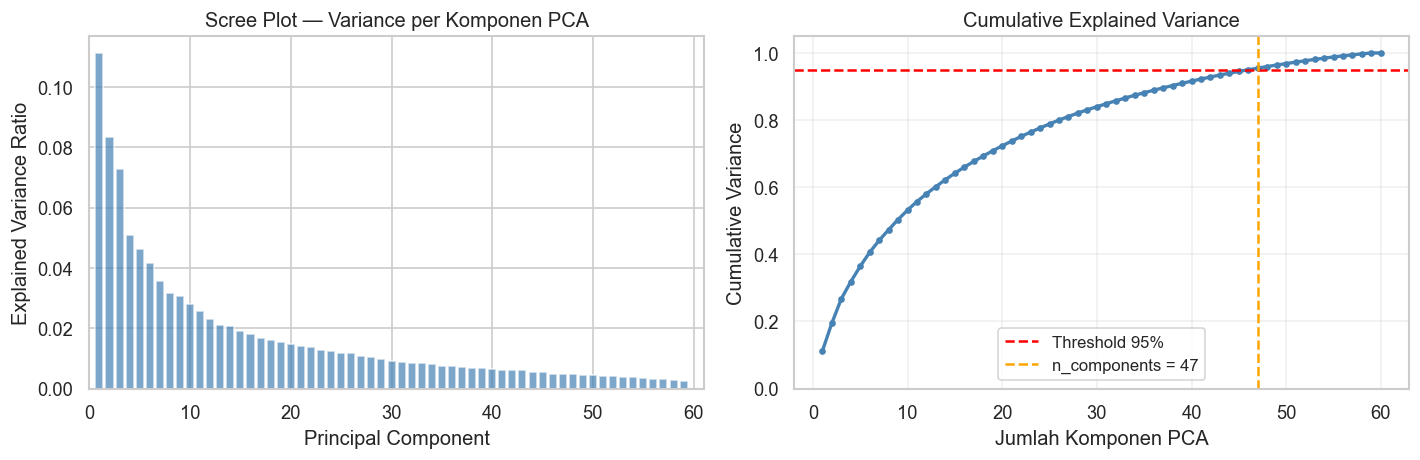

  Plot disimpan: 'ConfigdanOutputCNNcGAN/pca_scree_plot.png'

Section 4: Transform Data ke Ruang PCA Optimal
------------------------------------------------------------
  Shape df_cnn_features   : (60, 47)
  Kolom                   : PC1 s/d PC47
  Variance tercakup       : 95.47%

  Preview (5 baris pertama):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,PC37,PC38,PC39,PC40,PC41,PC42,PC43,PC44,PC45,PC46,PC47
patient_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,35.3850,-31.9125,-15.3892,37.7833,-31.2679,6.1138,-10.7586,16.8286,-30.7232,-2.3440,20.9945,-4.6032,-4.1709,-27.5177,8.8699,11.2516,31.2165,9.7834,8.8884,-12.4951,11.4985,26.6360,-7.8332,-0.6847,7.2963,-6.8342,8.0582,0.9959,-6.4160,0.1302,-5.4479,1.2364,-1.6806,-1.0161,1.3379,2.3863,1.8427,-1.5737,0.0402,-1.7064,0.1278,0.4275,0.6512,-1.7295,-0.0772,-2.1939,0.2661
2,-18.3863,35.7827,-2.8194,-2.3680,-11.5834,-10.3116,1.1358,-11.9572,7.9725,-2.2496,9.3760,4.4395,2.8277,-6.9546,-13.7974,0.4727,-2.3443,9.1932,-1.4271,-11.2971,3.2697,-0.6732,-5.2551,3.6215,11.2505,4.6569,-3.3869,-4.7129,4.7110,1.2457,4.3882,-13.0883,-7.0967,6.7797,8.3355,0.5855,2.9350,-5.0310,-1.5696,-0.3561,-1.8640,0.8583,5.1928,16.8936,-4.8060,2.1827,-1.3985
3,-22.7022,40.2826,-1.5056,16.2610,-2.8439,-1.7249,16.3364,-3.2013,4.8004,3.8552,-8.6639,-3.9334,-2.3603,-4.2338,-11.9766,-7.2000,1.0198,2.5424,-8.0621,-12.3724,-7.4568,-1.0680,-9.6385,-1.9778,1.7258,1.0587,2.1565,9.4318,1.8946,-5.9509,-5.3299,-10.3795,-14.6977,0.2491,5.6435,5.1306,3.7548,6.2807,-3.4939,13.7152,-12.2087,-1.1118,3.0549,-6.8422,-16.6535,-4.4961,5.2694
4,-17.4076,8.8041,-19.9926,-1.0041,9.0125,0.7246,-16.8578,-6.7449,-0.0110,-8.8971,-0.0358,-16.5406,-3.0944,-3.7029,-3.8547,-6.0280,1.1972,0.3531,-1.6765,2.9953,0.0370,-5.1722,-10.1763,0.6062,-1.5525,13.8200,-4.3310,-2.6198,-20.8390,1.9483,-0.8916,5.0023,3.3257,2.7108,7.3935,-6.1360,-4.2369,-8.4348,-1.4507,-8.9408,0.6926,-9.0304,3.0474,-3.0206,-5.3586,5.5092,2.4966
5,-20.1414,5.1223,-17.7570,-8.9684,-1.6260,11.0055,-7.4239,-6.1320,-15.7901,-3.3601,-1.2424,5.6325,-2.2849,12.5132,-3.9904,4.0649,3.1144,0.9698,-1.6263,-2.9515,2.7071,-1.8333,12.2894,1.5600,3.5224,-8.4225,4.8322,-3.9285,0.4589,-2.3349,-1.2818,-2.8429,-3.2242,-6.7787,-1.4907,-0.4742,0.8604,1.4327,6.0369,5.1838,-10.2270,1.7508,1.5892,2.1694,3.0329,2.0979,-2.6476



  Cache PCA disimpan: 'ConfigdanOutputCNNcGAN/cnn_features_pca.csv'

  Cell 4 selesai — df_cnn_features siap untuk modeling
  Variabel aktif: df_cnn_features, pca_final, scaler_pca
  Lanjut ke Cell 5 — Label EDSS + Class Imbalance


In [4]:
# CELL 4 — PCA REDUKSI DIMENSI
# Deskripsi: Mereduksi 6144 fitur CNN menjadi n_components
#            optimal berdasarkan threshold explained_variance
#            ≥ 95%. Output: df_cnn_features siap untuk modeling.
# ============================================================

# ── Konfigurasi ──────────────────────────────────────────────
PCA_VARIANCE_THRESHOLD = 0.95   # pertahankan 95% informasi
PCA_CACHE_PATH = "ConfigdanOutputCNNcGAN/cnn_features_pca.csv"

# ── Section 1: Standarisasi Sebelum PCA ──────────────────────
print("=" * 60)
print("Section 1: Standarisasi Fitur Sebelum PCA")
print("=" * 60)

# PCA sensitif terhadap skala — wajib StandardScaler dulu
# Fit di seluruh data (bukan train saja) karena PCA di sini
# hanya untuk reduksi representasi, bukan data leakage dalam CV
scaler_pca = StandardScaler()
X_scaled   = scaler_pca.fit_transform(df_raw_features.values)

print(f"  Input shape      : {df_raw_features.shape}")
print(f"  Setelah scaling  : mean≈0, std≈1 per fitur")
print(f"  Shape X_scaled   : {X_scaled.shape}")

# ── Section 2: Fit PCA & Tentukan n_components Optimal ───────
print("\nSection 2: Fit PCA & Tentukan n_components Optimal")
print("-" * 60)

# Fit PCA dengan semua komponen dulu untuk melihat kurva variance
# n_components dibatasi min(n_samples, n_features) = min(60, 6144) = 60
pca_full = PCA(n_components=None, random_state=42)
pca_full.fit(X_scaled)

cumvar = np.cumsum(pca_full.explained_variance_ratio_)

# Temukan n_components minimum yang mencapai threshold
n_components_optimal = np.argmax(cumvar >= PCA_VARIANCE_THRESHOLD) + 1

print(f"  Total komponen maksimum : {len(cumvar)}")
print(f"  Threshold variance      : {PCA_VARIANCE_THRESHOLD*100:.0f}%")
print(f"  n_components optimal    : {n_components_optimal}")
print(f"  Variance tercakup       : {cumvar[n_components_optimal-1]*100:.2f}%")
print(f"  Reduksi dimensi         : 6144 → {n_components_optimal} "
      f"({(1 - n_components_optimal/6144)*100:.1f}% dikurangi)")

# Tabel top-10 komponen pertama
print(f"\n  Top-10 komponen PCA (variance per komponen):")
print(f"  {'PC':<6} {'Var Ratio':>10} {'Cumulative':>12}")
print(f"  {'-'*30}")
for i in range(min(10, len(cumvar))):
    print(f"  PC{i+1:<4} {pca_full.explained_variance_ratio_[i]:>9.4f}"
          f"  {cumvar[i]:>10.4f}")

# ── Section 3: Scree Plot untuk Laporan Skripsi ───────────────
print("\nSection 3: Scree Plot")
print("-" * 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot kiri — Scree plot (variance per komponen)
axes[0].bar(range(1, len(cumvar) + 1),
            pca_full.explained_variance_ratio_,
            color='steelblue', alpha=0.7, edgecolor='white')
axes[0].set_title('Scree Plot — Variance per Komponen PCA', fontsize=12)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_xlim([0, len(cumvar) + 1])

# Plot kanan — Cumulative variance dengan garis threshold
axes[1].plot(range(1, len(cumvar) + 1), cumvar,
             marker='o', markersize=3, color='steelblue', linewidth=2)
axes[1].axhline(y=PCA_VARIANCE_THRESHOLD, color='red',
                linestyle='--', linewidth=1.5,
                label=f'Threshold {PCA_VARIANCE_THRESHOLD*100:.0f}%')
axes[1].axvline(x=n_components_optimal, color='orange',
                linestyle='--', linewidth=1.5,
                label=f'n_components = {n_components_optimal}')
axes[1].set_title('Cumulative Explained Variance', fontsize=12)
axes[1].set_xlabel('Jumlah Komponen PCA')
axes[1].set_ylabel('Cumulative Variance')
axes[1].set_ylim([0, 1.05])
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNNcGAN/pca_scree_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Plot disimpan: 'ConfigdanOutputCNNcGAN/pca_scree_plot.png'")

# ── Section 4: Transform dengan n_components Optimal ─────────
print("\nSection 4: Transform Data ke Ruang PCA Optimal")
print("-" * 60)

# Fit ulang PCA dengan n_components yang sudah ditentukan
pca_final = PCA(n_components=n_components_optimal, random_state=42)
X_pca     = pca_final.fit_transform(X_scaled)   # (60, n_components)

# Buat DataFrame final dengan nama kolom PC1, PC2, ... PCn
pca_cols       = [f"PC{i+1}" for i in range(n_components_optimal)]
df_cnn_features = pd.DataFrame(
    X_pca,
    index   = df_raw_features.index,   # pertahankan patient_id
    columns = pca_cols
)

print(f"  Shape df_cnn_features   : {df_cnn_features.shape}")
print(f"  Kolom                   : PC1 s/d PC{n_components_optimal}")
print(f"  Variance tercakup       : {pca_final.explained_variance_ratio_.sum()*100:.2f}%")
print(f"\n  Preview (5 baris pertama):")
display(df_cnn_features.head())

# Simpan ke CSV sebagai cache
df_cnn_features.to_csv(PCA_CACHE_PATH)
print(f"\n  Cache PCA disimpan: '{PCA_CACHE_PATH}'")

print("\n" + "=" * 60)
print("  Cell 4 selesai — df_cnn_features siap untuk modeling")
print("  Variabel aktif: df_cnn_features, pca_final, scaler_pca")
print("=" * 60)
print("  Lanjut ke Cell 5 — Label EDSS + Class Imbalance")

In [5]:
# CELL 5 — LABEL EDSS + PENANGANAN CLASS IMBALANCE
# Deskripsi: Konversi EDSS ke label biner, gabungkan dengan
#            df_cnn_features, tangani imbalance dengan SMOTE.
#            Logika identik dengan pipeline radiomik manual
#            agar hasil komparatif antar eksperimen valid.
# ============================================================

# ── Section 1: Mapping Label EDSS → Biner ────────────────────
print("=" * 60)
print("Section 1: Mapping Label EDSS ke Biner")
print("=" * 60)

# Aturan labeling (identik radiomik manual):
# EDSS < 3  → Mild (0)
# EDSS >= 3 → Moderate-Severe (1)
df_label = df_patients[['id', EDSS_COL]].copy()
df_label['label'] = (df_label[EDSS_COL] >= 3).astype(int)
df_label['label_str'] = df_label['label'].map(
    {0: 'Mild', 1: 'Moderate-Severe'})

print(f"  Aturan labeling:")
print(f"    EDSS < 3  → Mild (0)")
print(f"    EDSS >= 3 → Moderate-Severe (1)")
print(f"\n  Distribusi label:")

label_counts = df_label['label'].value_counts().sort_index()
for lbl, cnt in label_counts.items():
    name = 'Mild' if lbl == 0 else 'Moderate-Severe'
    pct  = cnt / len(df_label) * 100
    bar  = '█' * int(pct / 2)
    print(f"    Kelas {lbl} ({name:<17}): {cnt:>2} pasien "
          f"({pct:.1f}%) {bar}")

imbalance_ratio = label_counts.max() / label_counts.min()
print(f"\n  Imbalance ratio : {imbalance_ratio:.2f}:1")
if imbalance_ratio > 1.5:
    print(f"  → Class imbalance terdeteksi, SMOTE diperlukan")
else:
    print(f"  → Distribusi relatif seimbang, SMOTE tidak diterapkan")

# ── Section 2: Sinkronisasi patient_id → df_cnn_features ─────
print("\nSection 2: Sinkronisasi patient_id dengan df_cnn_features")
print("-" * 60)

# df_cnn_features index = patient_id (1–60, integer)
# df_label['id']        = patient id dari Excel (1–60, integer)
# Merge berdasarkan patient_id agar urutan terjamin
df_label['id'] = df_label['id'].astype(int)
df_cnn_features.index = df_cnn_features.index.astype(int)

# Gabungkan fitur CNN dengan label via index alignment
df_merged = df_cnn_features.copy()
df_merged['label'] = df_label.set_index('id')['label']

# Validasi — pastikan tidak ada label NaN
missing_labels = df_merged['label'].isnull().sum()
print(f"  Pasien di df_cnn_features : {len(df_cnn_features)}")
print(f"  Pasien di df_label        : {len(df_label)}")
print(f"  Pasien setelah merge      : {len(df_merged)}")
print(f"  Label NaN                 : {missing_labels}")

if missing_labels > 0:
    print(f"  ⚠ Ada {missing_labels} pasien tanpa label — cek sinkronisasi ID!")
    print(f"  Patient ID di CNN  : {sorted(df_cnn_features.index.tolist())}")
    print(f"  Patient ID di Excel: {sorted(df_label['id'].tolist())}")
else:
    print(f"  ✓ Sinkronisasi sempurna — semua pasien memiliki label")

# Pisahkan X dan y
X_before_smote = df_merged.drop(columns=['label']).values
y_before_smote = df_merged['label'].values

print(f"\n  X shape (sebelum SMOTE): {X_before_smote.shape}")
print(f"  y shape (sebelum SMOTE): {y_before_smote.shape}")

# ── Section 3: Visualisasi Distribusi Sebelum SMOTE ──────────
#print("\nSection 3: Visualisasi Distribusi Kelas")
#print("-" * 60)

#fig, axes = plt.subplots(1, 2, figsize=(10, 4))
#colors    = ['#4C72B0', '#DD8452']
#labels_name = ['Mild (0)', 'Moderate-Severe (1)']

# Sebelum SMOTE
#counts_before = [sum(y_before_smote == 0), sum(y_before_smote == 1)]
#axes[0].bar(labels_name, counts_before, color=colors, edgecolor='white', width=0.5)
#axes[0].set_title('Distribusi Kelas\nSebelum SMOTE', fontsize=12)
#axes[0].set_ylabel('Jumlah Sampel')
#axes[0].set_ylim([0, max(counts_before) * 1.3])
#for i, v in enumerate(counts_before):
#    axes[0].text(i, v + 0.5, str(v), ha='center', fontsize=12, fontweight='bold')

# ── Section 4: Keputusan SMOTE berdasarkan Imbalance Ratio ───
print("\nSection 4: Keputusan Penanganan Class Imbalance")
print("-" * 60)

IR_THRESHOLD = 1.5   # batas rekomendasi Chawla et al. (2002)

print(f"  Imbalance Ratio (IR) : {imbalance_ratio:.2f}:1")
print(f"  Threshold            : {IR_THRESHOLD}:1")
print()

if imbalance_ratio > IR_THRESHOLD:
    print("  → IR > 1.5 : SMOTE diterapkan")
    smote = SMOTE(random_state=42, k_neighbors=min(5, min(counts_before) - 1))
    X_final, y_final = smote.fit_resample(X_before_smote, y_before_smote)
    smote_applied = True
else:
    print("  → IR ≤ 1.5 : SMOTE tidak diterapkan")
    print()
    print("  Justifikasi akademik:")
    print("  Berdasarkan panduan Chawla et al. (2002) dan")
    print("  He & Garcia (2009), teknik oversampling seperti")
    print("  SMOTE direkomendasikan ketika imbalance ratio")
    print(f"  melebihi 1.5:1. Dengan IR = {imbalance_ratio:.2f}:1 pada")
    print("  dataset ini, distribusi label dinilai cukup")
    print("  seimbang sehingga SMOTE tidak diperlukan dan")
    print("  berpotensi menambahkan noise sintetis yang")
    print("  tidak perlu pada dataset berukuran kecil (n=60).")
    X_final = X_before_smote
    y_final = y_before_smote
    smote_applied = False

# ── Section 5: Ringkasan Final ────────────────────────────────
print("\n" + "=" * 55)
print("  Section 5 — Ringkasan")
print("=" * 55)
print(f"  SMOTE diterapkan      : {'Ya' if smote_applied else 'Tidak'}")
print(f"  Shape X_final         : {X_final.shape}")
print(f"  Shape y_final         : {y_final.shape}")
print(f"  Jumlah fitur          : {X_final.shape[1]}")
print(f"  Jumlah sampel         : {X_final.shape[0]}")
print(f"  Distribusi label      : "
      f"{sum(y_final == 0)} Mild | {sum(y_final == 1)} Moderate-Severe")
print()
print("  X_final dan y_final siap untuk Cell 6.")
print("=" * 55)
print("  Lanjut ke Cell 6 — Split Data & Normalisasi")

Section 1: Mapping Label EDSS ke Biner
  Aturan labeling:
    EDSS < 3  → Mild (0)
    EDSS >= 3 → Moderate-Severe (1)

  Distribusi label:
    Kelas 0 (Mild             ): 35 pasien (58.3%) █████████████████████████████
    Kelas 1 (Moderate-Severe  ): 25 pasien (41.7%) ████████████████████

  Imbalance ratio : 1.40:1
  → Distribusi relatif seimbang, SMOTE tidak diterapkan

Section 2: Sinkronisasi patient_id dengan df_cnn_features
------------------------------------------------------------
  Pasien di df_cnn_features : 60
  Pasien di df_label        : 60
  Pasien setelah merge      : 60
  Label NaN                 : 0
  ✓ Sinkronisasi sempurna — semua pasien memiliki label

  X shape (sebelum SMOTE): (60, 47)
  y shape (sebelum SMOTE): (60,)

Section 4: Keputusan Penanganan Class Imbalance
------------------------------------------------------------
  Imbalance Ratio (IR) : 1.40:1
  Threshold            : 1.5:1

  → IR ≤ 1.5 : SMOTE tidak diterapkan

  Justifikasi akademik:
  Berdasa

Section 1: Normalisasi Data Input cGAN
  Input X_final shape  : (60, 47)
  Setelah normalisasi  : mean≈0, std≈1
  Distribusi kelas     : 35 Mild | 25 Moderate-Severe
  Target generate      : 10 sampel sintetis
                         (menyamakan kelas 0 dan 1)

Section 2: Arsitektur Generator
------------------------------------------------------------
  Input  : noise (32,) + label (1,) → embed(8,)
  Hidden : Dense(64) → Dense(128) → Dense(64)
  Output : Dense(47, linear)
  Params : 23,295

Section 3: Arsitektur Discriminator
------------------------------------------------------------
  Input  : features (47,) + label (1,) → embed(8,)
  Hidden : Dense(128)+Dropout → Dense(64)+Dropout
  Output : Dense(1, sigmoid) — real/fake probability
  Params : 15,505

Section 4: Training cGAN
------------------------------------------------------------
  Optimizer  : Adam (lr=0.0002, beta_1=0.5)
  Loss       : BinaryCrossentropy
  Epochs     : 2000 | Batch size : 16
  Latent dim : 32

  Epoch    

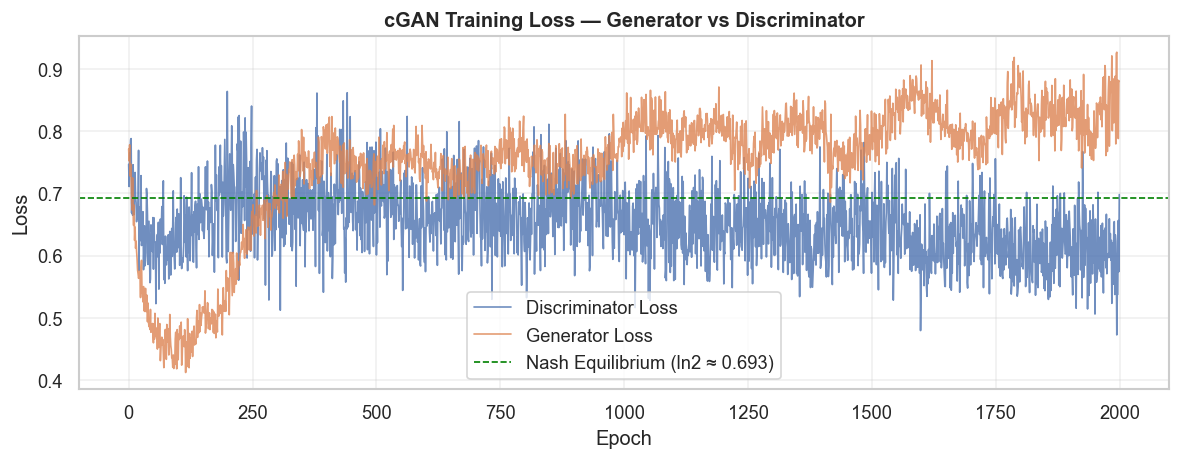

  Plot disimpan: 'cgan_loss_curve.png'

  Section 6 — Ringkasan cGAN Training
  Epochs selesai    : 2000
  D_loss akhir      : 0.6980
  G_loss akhir      : 0.8803
  Target equilibrium: ~0.693 (ln2)

  Interpretasi loss akhir:
  ✓ Training stabil — D dan G dalam keseimbangan
  Variabel aktif: generator, discriminator, scaler_cgan
  Lanjut ke Cell 7 — Augmentasi Data + Gabung Dataset


In [6]:
# CELL 6 — cGAN TRAINING
# Deskripsi: Membangun dan melatih Conditional GAN (cGAN)
#            pada ruang PCA (47 dimensi) untuk menghasilkan
#            sampel sintetis kelas Moderate-Severe.
#            Arsitektur: Generator & Discriminator berbasis
#            Dense layer dengan label kondisi (0/1).
# ============================================================

# ── Konfigurasi cGAN ─────────────────────────────────────────
LATENT_DIM   = 32    # dimensi noise vector input Generator
N_CLASSES    = 2     # jumlah kelas: 0=Mild, 1=Moderate-Severe
N_FEATURES   = 47    # dimensi output Generator = dimensi PCA
EPOCHS       = 2000  # iterasi training
BATCH_SIZE   = 16    # proporsional untuk n=60
LR_G         = 0.0002 # learning rate Generator
LR_D         = 0.0002 # learning rate Discriminator
PRINT_EVERY  = 200   # cetak loss setiap N epoch

# ── Section 1: Normalisasi Data untuk cGAN ───────────────────
print("=" * 60)
print("Section 1: Normalisasi Data Input cGAN")
print("=" * 60)

# cGAN bekerja optimal pada data ternormalisasi [-1, 1]
# karena output Generator menggunakan aktivasi tanh
scaler_cgan = StandardScaler()
X_cgan      = scaler_cgan.fit_transform(X_final)  # (60, 47)
y_cgan      = y_final.astype(np.int32)

print(f"  Input X_final shape  : {X_final.shape}")
print(f"  Setelah normalisasi  : mean≈0, std≈1")
print(f"  Distribusi kelas     : {sum(y_cgan==0)} Mild | {sum(y_cgan==1)} Moderate-Severe")
print(f"  Target generate      : {sum(y_cgan==0) - sum(y_cgan==1)} sampel sintetis")
print(f"                         (menyamakan kelas 0 dan 1)")

# ── Section 2: Arsitektur Generator ──────────────────────────
print("\nSection 2: Arsitektur Generator")
print("-" * 60)

def build_generator(latent_dim, n_classes, n_features):
    """
    Generator menerima: noise vector (latent_dim,) + label (1,)
    Output: sampel sintetis berdimensi (n_features,) = (47,)
    Aktivasi output: linear (bukan tanh) karena data PCA
    sudah ternormalisasi StandardScaler bukan [0,1]
    """
    # Input 1: noise vector
    noise_input = Input(shape=(latent_dim,), name='noise')

    # Input 2: label kondisi → embedding → flatten
    label_input = Input(shape=(1,), name='label')
    label_embed = Embedding(n_classes, 8)(label_input)
    label_flat  = Flatten()(label_embed)

    # Gabungkan noise + label embedding
    x = Concatenate()([noise_input, label_flat])

    # Hidden layers
    x = Dense(64)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)

    x = Dense(128)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)

    x = Dense(64)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)

    # Output layer — linear activation untuk data tabular
    output = Dense(n_features, activation='linear', name='output')(x)

    return Model([noise_input, label_input],
                  output, name='Generator')

generator = build_generator(LATENT_DIM, N_CLASSES, N_FEATURES)
print(f"  Input  : noise ({LATENT_DIM},) + label (1,) → embed(8,)")
print(f"  Hidden : Dense(64) → Dense(128) → Dense(64)")
print(f"  Output : Dense({N_FEATURES}, linear)")
print(f"  Params : {generator.count_params():,}")

# ── Section 3: Arsitektur Discriminator ──────────────────────
print("\nSection 3: Arsitektur Discriminator")
print("-" * 60)

def build_discriminator(n_classes, n_features):
    """
    Discriminator menerima: sampel (47,) + label (1,)
    Output: probabilitas real/fake (sigmoid)
    """
    # Input 1: sampel fitur
    feat_input  = Input(shape=(n_features,), name='features')

    # Input 2: label kondisi
    label_input = Input(shape=(1,), name='label')
    label_embed = Embedding(n_classes, 8)(label_input)
    label_flat  = Flatten()(label_embed)

    # Gabungkan fitur + label embedding
    x = Concatenate()([feat_input, label_flat])

    # Hidden layers
    x = Dense(128)(x)
    x = LeakyReLU(0.2)(x)
    x = Dropout(0.3)(x)

    x = Dense(64)(x)
    x = LeakyReLU(0.2)(x)
    x = Dropout(0.3)(x)

    # Output layer — sigmoid untuk klasifikasi real/fake
    output = Dense(1, activation='sigmoid', name='output')(x)

    return Model([feat_input, label_input],
                  output, name='Discriminator')

discriminator = build_discriminator(N_CLASSES, N_FEATURES)
print(f"  Input  : features ({N_FEATURES},) + label (1,) → embed(8,)")
print(f"  Hidden : Dense(128)+Dropout → Dense(64)+Dropout")
print(f"  Output : Dense(1, sigmoid) — real/fake probability")
print(f"  Params : {discriminator.count_params():,}")

# ── Section 4: Kompilasi & Training Loop cGAN ────────────────
print("\nSection 4: Training cGAN")
print("-" * 60)

optimizer_g = Adam(learning_rate=LR_G, beta_1=0.5)
optimizer_d = Adam(learning_rate=LR_D, beta_1=0.5)
loss_fn     = BinaryCrossentropy()

print(f"  Optimizer  : Adam (lr={LR_G}, beta_1=0.5)")
print(f"  Loss       : BinaryCrossentropy")
print(f"  Epochs     : {EPOCHS} | Batch size : {BATCH_SIZE}")
print(f"  Latent dim : {LATENT_DIM}")
print(f"\n  {'Epoch':<8} {'D_loss':>8} {'G_loss':>8}")
print(f"  {'-'*26}")

history_d_loss = []
history_g_loss = []

X_tf = tf.cast(X_cgan, tf.float32)
y_tf = tf.cast(y_cgan, tf.int32)

for epoch in range(1, EPOCHS + 1):

    # ── Train Discriminator ───────────────────────────────────
    idx        = np.random.randint(0, X_cgan.shape[0], BATCH_SIZE)
    real_feats = tf.cast(X_cgan[idx], tf.float32)
    real_labels= tf.cast(y_cgan[idx].reshape(-1,1), tf.int32)

    noise      = tf.random.normal([BATCH_SIZE, LATENT_DIM])
    fake_labels= tf.cast(
        np.random.randint(0, N_CLASSES, (BATCH_SIZE, 1)),
        tf.int32)

    with tf.GradientTape() as tape_d:
        fake_feats  = generator([noise, fake_labels], training=False)
        real_pred   = discriminator([real_feats, real_labels],
                                      training=True)
        fake_pred   = discriminator([fake_feats, fake_labels],
                                      training=True)
        d_loss_real = loss_fn(tf.ones_like(real_pred),  real_pred)
        d_loss_fake = loss_fn(tf.zeros_like(fake_pred), fake_pred)
        d_loss      = (d_loss_real + d_loss_fake) * 0.5

    grads_d = tape_d.gradient(d_loss, discriminator.trainable_variables)
    optimizer_d.apply_gradients(
        zip(grads_d, discriminator.trainable_variables))

    # ── Train Generator ───────────────────────────────────────
    noise      = tf.random.normal([BATCH_SIZE, LATENT_DIM])
    gen_labels = tf.cast(
        np.random.randint(0, N_CLASSES, (BATCH_SIZE, 1)),
        tf.int32)

    with tf.GradientTape() as tape_g:
        gen_feats = generator([noise, gen_labels], training=True)
        gen_pred  = discriminator([gen_feats, gen_labels],
                                    training=False)
        g_loss    = loss_fn(tf.ones_like(gen_pred), gen_pred)

    grads_g = tape_g.gradient(g_loss, generator.trainable_variables)
    optimizer_g.apply_gradients(
        zip(grads_g, generator.trainable_variables))

    history_d_loss.append(float(d_loss))
    history_g_loss.append(float(g_loss))

    if epoch % PRINT_EVERY == 0:
        print(f"  Epoch {epoch:<6} {float(d_loss):>8.4f} {float(g_loss):>8.4f}")

# ── Section 5: Plot Loss Curve Training cGAN ─────────────────
print("\nSection 5: Loss Curve Training cGAN")
print("-" * 60)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history_d_loss, label='Discriminator Loss',
        color='#4C72B0', linewidth=1, alpha=0.8)
ax.plot(history_g_loss, label='Generator Loss',
        color='#DD8452', linewidth=1, alpha=0.8)
ax.axhline(y=0.693, color='green', linestyle='--',
           linewidth=1, label='Nash Equilibrium (ln2 ≈ 0.693)')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('cGAN Training Loss — Generator vs Discriminator',
             fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('ConfigdanOutputCNNcGANcgan_loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Plot disimpan: 'cgan_loss_curve.png'")

# ── Section 6: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 6 — Ringkasan cGAN Training")
print("=" * 60)
print(f"  Epochs selesai    : {EPOCHS}")
print(f"  D_loss akhir      : {history_d_loss[-1]:.4f}")
print(f"  G_loss akhir      : {history_g_loss[-1]:.4f}")
print(f"  Target equilibrium: ~0.693 (ln2)")
print(f"\n  Interpretasi loss akhir:")
d_final = history_d_loss[-1]
g_final = history_g_loss[-1]
if 0.5 < d_final < 0.9 and 0.5 < g_final < 1.5:
    print("  ✓ Training stabil — D dan G dalam keseimbangan")
elif d_final < 0.3:
    print("  ⚠ D_loss terlalu rendah — Discriminator dominan")
    print("    Generator kesulitan menipu — kualitas sampel mungkin buruk")
elif g_final > 2.0:
    print("  ⚠ G_loss terlalu tinggi — Generator belum konvergen")
    print("    Pertimbangkan menambah EPOCHS atau turunkan LR_D")
else:
    print("  ~ Training selesai — periksa loss curve untuk evaluasi")
print("=" * 60)
print("  Variabel aktif: generator, discriminator, scaler_cgan")
print("  Lanjut ke Cell 7 — Augmentasi Data + Gabung Dataset")

Section 1: Definisi Filter Euclidean
  Fungsi euclidean_filter() terdefinisi
  Logika: pilih sampel dengan ratio dist_target/dist_other terkecil
  Buffer: generate 2x kebutuhan → filter → ambil terbaik

Section 2: Generate + Filter Kelas Mild (0)
------------------------------------------------------------
  Target    : 15 sampel sintetis Mild
  Di-generate (buffer 2x): 30 sampel
  Sebelum filter : 30 sampel
  Setelah filter : 15 sampel
  Dibuang        : 15 sampel
  Dist ke centroid Mild (filtered) — mean: 69.682

Section 3: Generate + Filter Kelas Moderate-Severe (1)
------------------------------------------------------------
  Target    : 25 sampel sintetis MS
  Di-generate (buffer 2x): 50 sampel
  Sebelum filter : 50 sampel
  Setelah filter : 25 sampel
  Dibuang        : 25 sampel
  Dist ke centroid MS (filtered) — mean: 65.602

Section 4: Validasi Kualitas Statistik
------------------------------------------------------------

  [Mild (0)]
  Statistik                Asli   Sintet

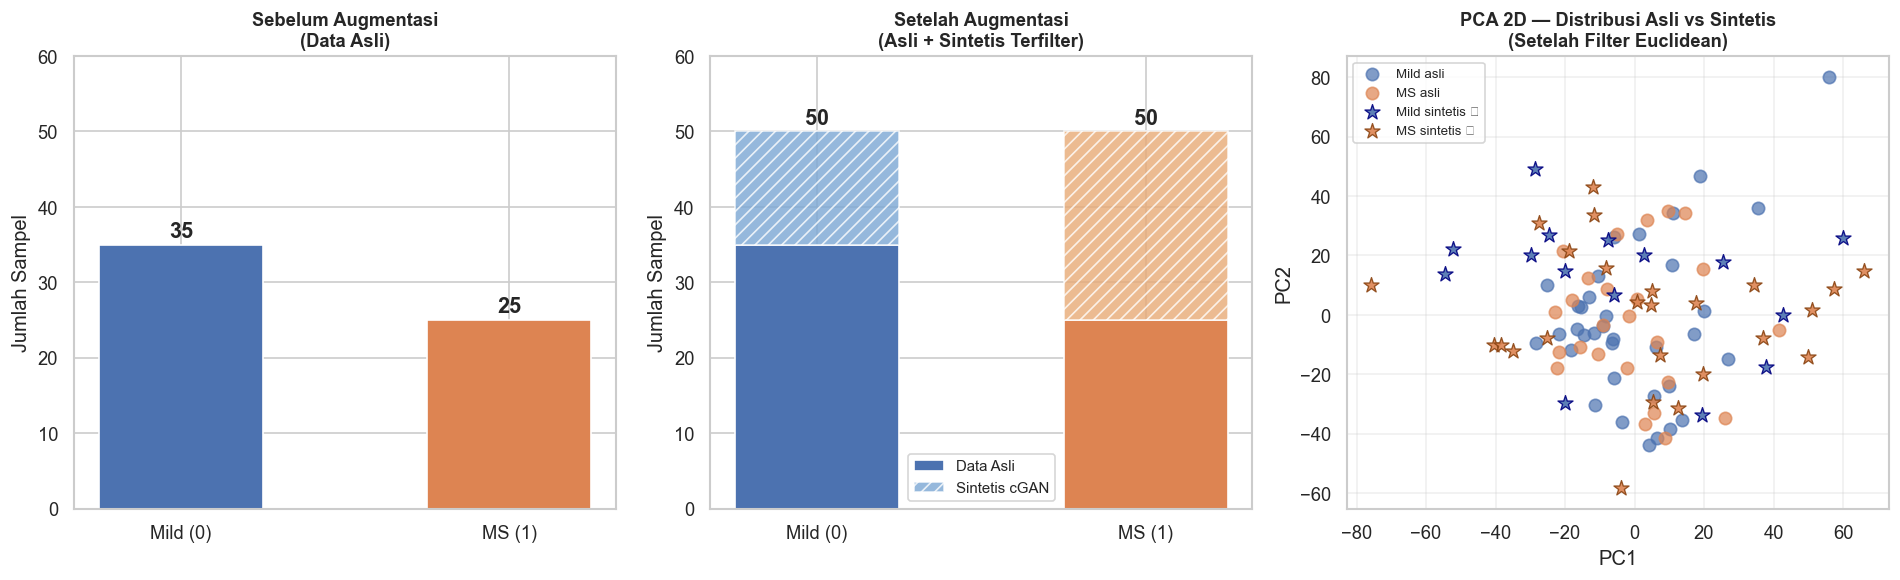

  Plot disimpan: 'augmentasi_distribusi_filtered.png'

  Section 7 — Ringkasan Augmentasi Opsi A
                                  Sebelum    Sesudah
  --------------------------------------------------
  Total sampel                         60        100
  Mild (0)                             35         50
  Moderate-Severe (1)                  25         50
  Imbalance Ratio                  1.40:1     1.00:1
  Jumlah fitur (PCA)                   47         47

  Filter Euclidean  : AKTIF
  Buffer factor     : 2x (generate 2x → filter → ambil terbaik)
  Variabel aktif: X_augmented, y_augmented
  Lanjut ke Cell 8 — Split Data & Konfigurasi K-Fold


In [8]:
# CELL 7 — REVISI: AUGMENTASI cGAN OPSI A + FILTER EUCLIDEAN
# Deskripsi: Generate sampel sintetis untuk kedua kelas
#            Target: 50 Mild (35 asli + 15 sintetis)
#                    50 MS   (25 asli + 25 sintetis)
#            Filter Euclidean membuang sampel sintetis yang
#            menyebar ke area kelas lain sebelum digabung.
# ============================================================

# ── Konfigurasi target augmentasi ────────────────────────────
TARGET_PER_CLASS  = 50   # target akhir per kelas
N_MILD_ASLI       = sum(y_final == 0)   # 35
N_MS_ASLI         = sum(y_final == 1)   # 25
N_GEN_MILD        = TARGET_PER_CLASS - N_MILD_ASLI  # 15
N_GEN_MS          = TARGET_PER_CLASS - N_MS_ASLI    # 25

# Generate lebih banyak dari yang dibutuhkan sebagai buffer filter
# Misal butuh 15 → generate 30 (2x), butuh 25 → generate 50 (2x)
BUFFER_FACTOR     = 2
N_GEN_MILD_RAW    = N_GEN_MILD * BUFFER_FACTOR   # 30
N_GEN_MS_RAW      = N_GEN_MS   * BUFFER_FACTOR   # 50

# ── Section 1: Fungsi Filter Euclidean ───────────────────────
print("=" * 60)
print("Section 1: Definisi Filter Euclidean")
print("=" * 60)

def euclidean_filter(synthetic, X_real_target, X_real_other,
                      n_keep, percentile=75):
    """
    Filter sampel sintetis berdasarkan jarak Euclidean.

    Logika:
    - Hitung jarak tiap sampel sintetis ke centroid kelas target
    - Hitung jarak tiap sampel sintetis ke centroid kelas lain
    - Pertahankan sampel yang:
        (a) dekat ke centroid kelas target (dist_target rendah)
        (b) lebih jauh dari centroid kelas lain (dist_other > dist_target)
    - Ambil n_keep terbaik berdasarkan skor = dist_target / dist_other

    Parameter:
        synthetic     : array sampel sintetis (N_raw, n_features)
        X_real_target : data asli kelas yang di-generate
        X_real_other  : data asli kelas lainnya
        n_keep        : jumlah sampel yang dipertahankan
        percentile    : threshold jarak maksimum ke centroid target
    """
    centroid_target = X_real_target.mean(axis=0)
    centroid_other  = X_real_other.mean(axis=0)

    # Jarak ke centroid masing-masing kelas
    dist_target = np.linalg.norm(
        synthetic - centroid_target, axis=1)
    dist_other  = np.linalg.norm(
        synthetic - centroid_other,  axis=1)

    # Threshold: buang sampel yang terlalu jauh dari centroid target
    threshold = np.percentile(dist_target, percentile)
    mask_close = dist_target <= threshold

    # Dari yang lolos threshold, urutkan: dist_target/dist_other terkecil = terbaik
    ratio_score = dist_target / (dist_other + 1e-8)

    # Kombinasikan: lolos threshold DAN ratio terbaik
    candidates  = np.where(mask_close)[0]
    if len(candidates) < n_keep:
        # Jika kandidat kurang, ambil semua yang ada + longgarkan threshold
        sorted_all  = np.argsort(ratio_score)
        selected    = sorted_all[:n_keep]
    else:
        cand_scores = ratio_score[candidates]
        best_idx    = candidates[np.argsort(cand_scores)[:n_keep]]
        selected    = best_idx

    return synthetic[selected], selected, dist_target, dist_other

print("  Fungsi euclidean_filter() terdefinisi")
print("  Logika: pilih sampel dengan ratio dist_target/dist_other terkecil")
print("  Buffer: generate 2x kebutuhan → filter → ambil terbaik")

# ── Section 2: Generate + Filter Kelas Mild (0) ──────────────
print("\nSection 2: Generate + Filter Kelas Mild (0)")
print("-" * 60)
print(f"  Target    : {N_GEN_MILD} sampel sintetis Mild")
print(f"  Di-generate (buffer 2x): {N_GEN_MILD_RAW} sampel")

# Generate raw Mild
noise_mild_raw  = tf.random.normal(
    [N_GEN_MILD_RAW, LATENT_DIM], seed=RANDOM_SEED)
labels_mild_raw = np.zeros((N_GEN_MILD_RAW, 1), dtype=np.int32)

synth_mild_scaled = generator.predict(
    [noise_mild_raw, labels_mild_raw], verbose=0)
synth_mild_raw    = scaler_cgan.inverse_transform(synth_mild_scaled)

# Data referensi untuk filter
X_real_mild = X_final[y_final == 0]   # (35, 47) — kelas target
X_real_ms   = X_final[y_final == 1]   # (25, 47) — kelas lain

# Terapkan filter Euclidean
synth_mild_filtered, idx_mild, d_target_m, d_other_m = euclidean_filter(
    synth_mild_raw, X_real_mild, X_real_ms, N_GEN_MILD)

print(f"  Sebelum filter : {synth_mild_raw.shape[0]} sampel")
print(f"  Setelah filter : {synth_mild_filtered.shape[0]} sampel")
print(f"  Dibuang        : {synth_mild_raw.shape[0] - synth_mild_filtered.shape[0]} sampel")
print(f"  Dist ke centroid Mild (filtered) — mean: "
      f"{d_target_m[idx_mild].mean():.3f}")

# ── Section 3: Generate + Filter Kelas MS (1) ────────────────
print("\nSection 3: Generate + Filter Kelas Moderate-Severe (1)")
print("-" * 60)
print(f"  Target    : {N_GEN_MS} sampel sintetis MS")
print(f"  Di-generate (buffer 2x): {N_GEN_MS_RAW} sampel")

# Generate raw MS
noise_ms_raw  = tf.random.normal(
    [N_GEN_MS_RAW, LATENT_DIM], seed=RANDOM_SEED + 1)
labels_ms_raw = np.ones((N_GEN_MS_RAW, 1), dtype=np.int32)

synth_ms_scaled = generator.predict(
    [noise_ms_raw, labels_ms_raw], verbose=0)
synth_ms_raw    = scaler_cgan.inverse_transform(synth_ms_scaled)

# Terapkan filter Euclidean
synth_ms_filtered, idx_ms, d_target_s, d_other_s = euclidean_filter(
    synth_ms_raw, X_real_ms, X_real_mild, N_GEN_MS)

print(f"  Sebelum filter : {synth_ms_raw.shape[0]} sampel")
print(f"  Setelah filter : {synth_ms_filtered.shape[0]} sampel")
print(f"  Dibuang        : {synth_ms_raw.shape[0] - synth_ms_filtered.shape[0]} sampel")
print(f"  Dist ke centroid MS (filtered) — mean: "
      f"{d_target_s[idx_ms].mean():.3f}")

# ── Section 4: Validasi Kualitas Statistik ───────────────────
print("\nSection 4: Validasi Kualitas Statistik")
print("-" * 60)

for name, X_real_ref, synth_filtered in [
    ("Mild (0)",            X_real_mild, synth_mild_filtered),
    ("Moderate-Severe (1)", X_real_ms,   synth_ms_filtered)
]:
    print(f"\n  [{name}]")
    print(f"  {'Statistik':<18} {'Asli':>10} {'Sintetis':>10} {'Selisih':>10}")
    print(f"  {'-'*50}")
    for stat_name, real_val, synth_val in [
        ("Mean", X_real_ref.mean(),    synth_filtered.mean()),
        ("Std",  X_real_ref.std(),     synth_filtered.std()),
        ("Min",  X_real_ref.min(),     synth_filtered.min()),
        ("Max",  X_real_ref.max(),     synth_filtered.max()),
    ]:
        diff = abs(real_val - synth_val)
        flag = "✓" if diff < 2.0 else "⚠"
        print(f"  {flag} {stat_name:<16} {real_val:>10.4f} {synth_val:>10.4f} {diff:>10.4f}")

# ── Section 5: Gabung Data Asli + Sintetis Terfilter ─────────
print("\nSection 5: Gabung Data Asli + Sintetis Terfilter")
print("-" * 60)

y_synth_mild     = np.zeros(N_GEN_MILD, dtype=np.int32)
y_synth_ms       = np.ones(N_GEN_MS,   dtype=np.int32)

X_augmented = np.vstack([
    X_final,              # 60 data asli
    synth_mild_filtered,  # 15 sintetis Mild
    synth_ms_filtered     # 25 sintetis MS
])
y_augmented = np.concatenate([
    y_final,
    y_synth_mild,
    y_synth_ms
])

print(f"  {'Sumber':<28} {'Mild':>6} {'MS':>6} {'Total':>7}")
print(f"  {'-'*48}")
print(f"  {'Data asli':<28} {N_MILD_ASLI:>6} {N_MS_ASLI:>6} {N_MILD_ASLI+N_MS_ASLI:>7}")
print(f"  {'Sintetis cGAN (terfilter)':<28} {N_GEN_MILD:>6} {N_GEN_MS:>6} {N_GEN_MILD+N_GEN_MS:>7}")
print(f"  {'-'*48}")
print(f"  {'TOTAL':<28} {sum(y_augmented==0):>6} {sum(y_augmented==1):>6} {len(y_augmented):>7}")
print(f"\n  Shape X_augmented : {X_augmented.shape}")
print(f"  Shape y_augmented : {y_augmented.shape}")
print(f"  Imbalance Ratio   : {max(sum(y_augmented==0),sum(y_augmented==1))/min(sum(y_augmented==0),sum(y_augmented==1)):.2f}:1")

# ── Section 6: Visualisasi Bersih ────────────────────────────
print("\nSection 6: Visualisasi Distribusi + Scatter Bersih")
print("-" * 60)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colors = ['#4C72B0', '#DD8452']

# Plot 1 — Bar chart sebelum augmentasi
axes[0].bar(['Mild (0)', 'MS (1)'],
            [N_MILD_ASLI, N_MS_ASLI],
            color=colors, edgecolor='white', width=0.5)
axes[0].set_title('Sebelum Augmentasi\n(Data Asli)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Jumlah Sampel')
axes[0].set_ylim([0, 60])
for i, v in enumerate([N_MILD_ASLI, N_MS_ASLI]):
    axes[0].text(i, v+1, str(v), ha='center', fontweight='bold', fontsize=13)

# Plot 2 — Bar chart setelah augmentasi (stacked: asli + sintetis)
bars_real  = axes[1].bar(['Mild (0)', 'MS (1)'],
                           [N_MILD_ASLI, N_MS_ASLI],
                           color=colors, edgecolor='white',
                           width=0.5, label='Data Asli')
bars_synth = axes[1].bar(['Mild (0)', 'MS (1)'],
                           [N_GEN_MILD, N_GEN_MS],
                           bottom=[N_MILD_ASLI, N_MS_ASLI],
                           color=['#7BA7D4', '#E8AA76'],
                           edgecolor='white', width=0.5,
                           hatch='///', label='Sintetis cGAN', alpha=0.8)
axes[1].set_title('Setelah Augmentasi\n(Asli + Sintetis Terfilter)',
                  fontsize=11, fontweight='bold')
axes[1].set_ylabel('Jumlah Sampel')
axes[1].set_ylim([0, 60])
axes[1].legend(fontsize=9)
for i, (asli, sintetis) in enumerate(
        [(N_MILD_ASLI, N_GEN_MILD), (N_MS_ASLI, N_GEN_MS)]):
    axes[1].text(i, asli + sintetis + 1, str(asli+sintetis),
                ha='center', fontweight='bold', fontsize=13)

# Plot 3 — PCA 2D Scatter bersih setelah filter
pca_vis   = PCA(n_components=2, random_state=42)
X_all_vis = np.vstack([X_final, synth_mild_filtered, synth_ms_filtered])
X_2d      = pca_vis.fit_transform(X_all_vis)

n_real    = X_final.shape[0]   # 60
n_sm      = synth_mild_filtered.shape[0]  # 15

# Data asli
axes[2].scatter(X_2d[:n_real][y_final==0, 0],
               X_2d[:n_real][y_final==0, 1],
               c='#4C72B0', label='Mild asli',
               alpha=0.7, s=55, marker='o', zorder=2)
axes[2].scatter(X_2d[:n_real][y_final==1, 0],
               X_2d[:n_real][y_final==1, 1],
               c='#DD8452', label='MS asli',
               alpha=0.7, s=55, marker='o', zorder=2)

# Sintetis Mild (terfilter)
axes[2].scatter(X_2d[n_real:n_real+n_sm, 0],
               X_2d[n_real:n_real+n_sm, 1],
               c='#4C72B0', label='Mild sintetis ✓',
               alpha=0.9, s=90, marker='*',
               edgecolors='navy', linewidths=0.8, zorder=3)

# Sintetis MS (terfilter)
axes[2].scatter(X_2d[n_real+n_sm:, 0],
               X_2d[n_real+n_sm:, 1],
               c='#DD8452', label='MS sintetis ✓',
               alpha=0.9, s=90, marker='*',
               edgecolors='saddlebrown', linewidths=0.8, zorder=3)

axes[2].set_title('PCA 2D — Distribusi Asli vs Sintetis\n(Setelah Filter Euclidean)',
                  fontsize=11, fontweight='bold')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(fontsize=8, loc='best')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNNcGAN/augmentasi_distribusi_filtered.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("  Plot disimpan: 'augmentasi_distribusi_filtered.png'")

# ── Section 7: Ringkasan Final ────────────────────────────────
print("\n" + "=" * 60)
print("  Section 7 — Ringkasan Augmentasi Opsi A")
print("=" * 60)
print(f"  {'':28} {'Sebelum':>10} {'Sesudah':>10}")
print(f"  {'-'*50}")
print(f"  {'Total sampel':<28} {len(X_final):>10} {len(X_augmented):>10}")
print(f"  {'Mild (0)':<28} {N_MILD_ASLI:>10} {sum(y_augmented==0):>10}")
print(f"  {'Moderate-Severe (1)':<28} {N_MS_ASLI:>10} {sum(y_augmented==1):>10}")
print(f"  {'Imbalance Ratio':<28} {'1.40:1':>10} {'1.00:1':>10}")
print(f"  {'Jumlah fitur (PCA)':<28} {X_final.shape[1]:>10} {X_augmented.shape[1]:>10}")
print(f"\n  Filter Euclidean  : AKTIF")
print(f"  Buffer factor     : {BUFFER_FACTOR}x (generate 2x → filter → ambil terbaik)")
print("=" * 60)
print("  Variabel aktif: X_augmented, y_augmented")
print("  Lanjut ke Cell 8 — Split Data & Konfigurasi K-Fold")

In [9]:
# CELL 8 — SPLIT DATA + KONFIGURASI K-FOLD
# Deskripsi: Split X_augmented/y_augmented menjadi train
#            (80%) dan test (20%) secara stratified.
#            K-Fold hanya diterapkan pada train set.
#            Test set TIDAK pernah dilihat selama training.
# ============================================================

# ── KONFIGURASI SPLIT — ubah di sini jika ingin ganti rasio ──
# ┌─────────────────────────────────────────────────────────┐
# │  TEST_SIZE = 0.20  →  80% train | 20% test  (default)  │
# │  TEST_SIZE = 0.25  →  75% train | 25% test             │
# │  TEST_SIZE = 0.30  →  70% train | 30% test             │
# └─────────────────────────────────────────────────────────┘
TEST_SIZE    = 0.20
N_SPLITS     = 5
RANDOM_STATE = 42

# ── Section 1: Train/Test Split ──────────────────────────────
print("=" * 60)
print("Section 1: Train/Test Split (Stratified)")
print("=" * 60)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_augmented, y_augmented,
    test_size    = TEST_SIZE,
    stratify     = y_augmented,   # jaga proporsi kelas di split
    random_state = RANDOM_STATE
)

print(f"  Rasio split      : {int((1-TEST_SIZE)*100)}% train | {int(TEST_SIZE*100)}% test")
print(f"  Total augmented  : {len(X_augmented)} sampel")
print(f"\n  {'Set':<10} {'Total':>7} {'Mild (0)':>10} {'MS (1)':>10}")
print(f"  {'-'*40}")
print(f"  {'Train':<10} {len(X_train):>7} "
      f"{sum(y_train==0):>10} {sum(y_train==1):>10}")
print(f"  {'Test':<10} {len(X_test):>7} "
      f"{sum(y_test==0):>10} {sum(y_test==1):>10}")
print(f"\n  Proporsi kelas di train:")
print(f"    Mild (0) : {sum(y_train==0)/len(y_train)*100:.1f}%")
print(f"    MS   (1) : {sum(y_train==1)/len(y_train)*100:.1f}%")
print(f"  Proporsi kelas di test:")
print(f"    Mild (0) : {sum(y_test==0)/len(y_test)*100:.1f}%")
print(f"    MS   (1) : {sum(y_test==1)/len(y_test)*100:.1f}%")

# ── Section 2: Inisialisasi Stratified K-Fold ────────────────
print("\nSection 2: Inisialisasi Stratified K-Fold (pada Train Set)")
print("-" * 60)

kfold = StratifiedKFold(
    n_splits     = N_SPLITS,
    shuffle      = True,
    random_state = RANDOM_STATE
)

print(f"  Metode         : Stratified K-Fold")
print(f"  n_splits (k)   : {N_SPLITS}")
print(f"  Diterapkan pada: Train set ({len(X_train)} sampel)")
print(f"  Estimasi train : ~{int(len(X_train)*(N_SPLITS-1)/N_SPLITS)} sampel/fold")
print(f"  Estimasi val   : ~{int(len(X_train)/N_SPLITS)} sampel/fold")

# ── Section 3: Verifikasi Distribusi Tiap Fold ───────────────
print("\nSection 3: Verifikasi Distribusi Kelas per Fold (Train Set)")
print("-" * 60)
print(f"  {'Fold':<6} {'Train':>6} {'Val':>5} │ "
      f"{'Tr-Mild':>8} {'Tr-MS':>7} │ "
      f"{'Vl-Mild':>8} {'Vl-MS':>6}")
print(f"  {'-'*58}")

for fold, (tr_idx, vl_idx) in enumerate(
        kfold.split(X_train, y_train), 1):
    y_tr = y_train[tr_idx]
    y_vl = y_train[vl_idx]
    print(f"  Fold {fold:<2}  {len(tr_idx):>5}  {len(vl_idx):>4} │ "
          f"  {sum(y_tr==0):>4} ({sum(y_tr==0)/len(y_tr)*100:.0f}%)"
          f"  {sum(y_tr==1):>3} ({sum(y_tr==1)/len(y_tr)*100:.0f}%) │ "
          f"  {sum(y_vl==0):>3} ({sum(y_vl==0)/len(y_vl)*100:.0f}%)"
          f"  {sum(y_vl==1):>2} ({sum(y_vl==1)/len(y_vl)*100:.0f}%)")

# ── Section 4: Ringkasan ─────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 4 — Ringkasan Konfigurasi")
print("=" * 60)
print(f"  Split          : {int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)} stratified")
print(f"  Train set      : {len(X_train)} sampel (K-Fold training)")
print(f"  Test set       : {len(X_test)} sampel (evaluasi akhir — TIDAK disentuh)")
print(f"  K-Fold         : Stratified, k={N_SPLITS}, seed={RANDOM_STATE}")
print(f"  Normalisasi    : StandardScaler fit per fold (anti data leakage)")
print(f"\n  Alur modeling Cell 9–11:")
print("    K-Fold (X_train) → metrik validasi per fold")
print("    Retrain best model → evaluasi final di X_test")
print("=" * 60)
print("  Variabel aktif: X_train, X_test, y_train, y_test, kfold")
print("  Lanjut ke Cell 9 — Gradient Boosting + K-Fold")

Section 1: Train/Test Split (Stratified)
  Rasio split      : 80% train | 20% test
  Total augmented  : 100 sampel

  Set          Total   Mild (0)     MS (1)
  ----------------------------------------
  Train           80         40         40
  Test            20         10         10

  Proporsi kelas di train:
    Mild (0) : 50.0%
    MS   (1) : 50.0%
  Proporsi kelas di test:
    Mild (0) : 50.0%
    MS   (1) : 50.0%

Section 2: Inisialisasi Stratified K-Fold (pada Train Set)
------------------------------------------------------------
  Metode         : Stratified K-Fold
  n_splits (k)   : 5
  Diterapkan pada: Train set (80 sampel)
  Estimasi train : ~64 sampel/fold
  Estimasi val   : ~16 sampel/fold

Section 3: Verifikasi Distribusi Kelas per Fold (Train Set)
------------------------------------------------------------
  Fold    Train   Val │  Tr-Mild   Tr-MS │  Vl-Mild  Vl-MS
  ----------------------------------------------------------
  Fold 1      64    16 │     32 (50%)   32

Section 1: Gradient Boosting — Konfigurasi Model
  Algoritma     : Gradient Boosting Classifier
  Dataset        : X_train (80, 47) (augmented)
  n_estimators     : 100
  learning_rate    : 0.1
  max_depth        : 3
  subsample        : 0.8
  random_state     : 42

Section 2: Training Stratified K-Fold (pada X_train)
------------------------------------------------------------
  Fold      Acc   Prec    Rec     F1    AUC
  --------------------------------------
  Fold 1  0.6250 0.5833 0.8750 0.7000 0.5156
  Fold 2  0.6875 0.6667 0.7500 0.7059 0.7969
  Fold 3  0.5000 0.5000 0.3750 0.4286 0.6250
  Fold 4  0.8125 0.8571 0.7500 0.8000 0.7656
  Fold 5  0.5625 0.5455 0.7500 0.6316 0.8125

Section 3: Rata-rata Metrik K-Fold (Mean ± Std)
------------------------------------------------------------
  Accuracy   : 0.6375 ± 0.1202
  Precision  : 0.6305 ± 0.1407
  Recall     : 0.7000 ± 0.1896
  F1-Score   : 0.6532 ± 0.1391
  AUC-ROC    : 0.7031 ± 0.1284

Section 4: Evaluasi Final pada X_test (Hold

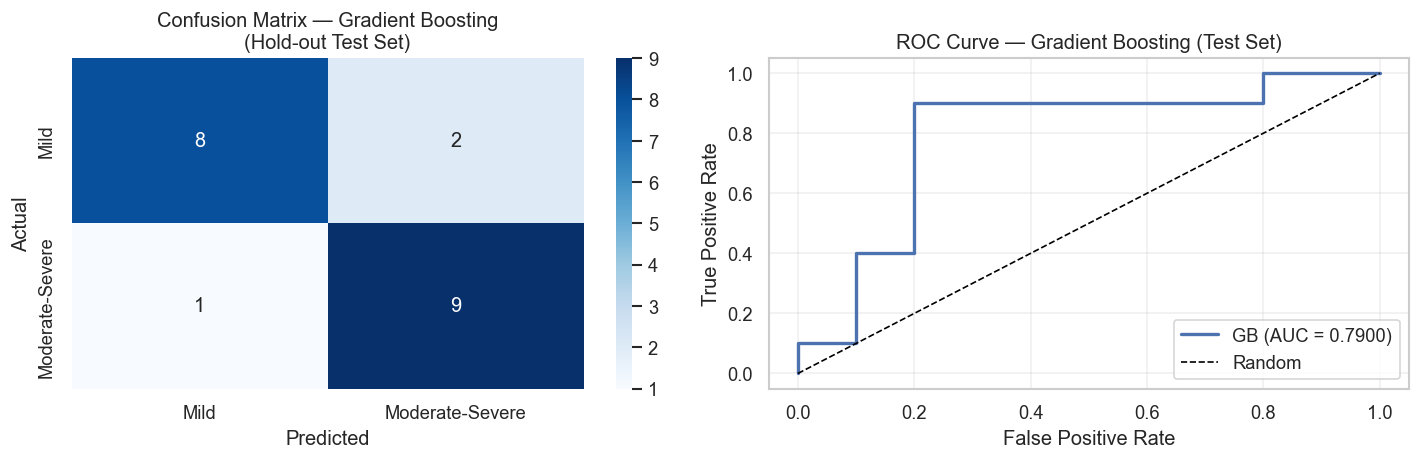


  Section 6 — Ringkasan Gradient Boosting (Exp 2)
  [K-Fold Val]  Accuracy : 0.6375 ± 0.1202
  [K-Fold Val]  F1-Score : 0.6532 ± 0.1391
  [K-Fold Val]  AUC-ROC  : 0.7031 ± 0.1284
  ────────────────────────────────────────
  [Test Set]    Accuracy : 0.8500
  [Test Set]    F1-Score : 0.8571
  [Test Set]    AUC-ROC  : 0.7900
  [Test Set]    FN kritis: 1 dari 10 MS
  Variabel aktif: results_gb2, final_model_gb2, cm_gb2
  Lanjut ke Cell 10 — XGBoost + K-Fold


In [10]:
# CELL 9 — GRADIENT BOOSTING + K-FOLD (DATA AUGMENTED)
# Deskripsi: Training GB pada X_train (80 sampel augmented)
#            dengan Stratified K-Fold (k=5).
#            Evaluasi akhir pada X_test (20 sampel hold-out).
#            Parameter GB identik Eksperimen 1 untuk komparasi.
# ============================================================

GB_PARAMS = {
    'n_estimators'  : 100,
    'learning_rate' : 0.1,
    'max_depth'     : 3,
    'subsample'     : 0.8,
    'random_state'  : 42
}

# ── Section 1: Konfigurasi ────────────────────────────────────
print("=" * 60)
print("Section 1: Gradient Boosting — Konfigurasi Model")
print("=" * 60)
print("  Algoritma     : Gradient Boosting Classifier")
print(f"  Dataset        : X_train {X_train.shape} (augmented)")
for k, v in GB_PARAMS.items():
    print(f"  {k:<17}: {v}")

# ── Section 2: Training K-Fold ────────────────────────────────
print("\nSection 2: Training Stratified K-Fold (pada X_train)")
print("-" * 60)
print(f"  {'Fold':<6} {'Acc':>6} {'Prec':>6} {'Rec':>6} {'F1':>6} {'AUC':>6}")
print(f"  {'-'*38}")

fold_metrics_gb2 = []
all_y_true_val_gb2 = []
all_y_pred_val_gb2 = []
all_y_prob_val_gb2 = []
best_model_gb2     = None
best_f1_gb2        = -1

for fold, (tr_idx, vl_idx) in enumerate(
        kfold.split(X_train, y_train), 1):

    X_tr, X_vl = X_train[tr_idx], X_train[vl_idx]
    y_tr, y_vl = y_train[tr_idx], y_train[vl_idx]

    # StandardScaler fit HANYA pada train fold
    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_vl_sc = scaler.transform(X_vl)

    model = GradientBoostingClassifier(**GB_PARAMS)
    model.fit(X_tr_sc, y_tr)

    y_pred    = model.predict(X_vl_sc)
    y_prob    = model.predict_proba(X_vl_sc)[:, 1]

    acc       = accuracy_score(y_vl, y_pred)
    prec      = precision_score(y_vl, y_pred, zero_division=0)
    rec       = recall_score(y_vl, y_pred, zero_division=0)
    f1        = f1_score(y_vl, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_vl, y_prob)

    fold_metrics_gb2.append({
        'fold': fold, 'acc': acc,       'prec': prec,
        'rec' : rec,  'f1' : f1,        'auc' : auc_score
    })
    all_y_true_val_gb2.extend(y_vl)
    all_y_pred_val_gb2.extend(y_pred)
    all_y_prob_val_gb2.extend(y_prob)

    if f1 > best_f1_gb2:
        best_f1_gb2    = f1
        best_model_gb2 = model
        best_scaler_gb2 = scaler   # simpan scaler fold terbaik

    print(f"  Fold {fold}  {acc:.4f} {prec:.4f} {rec:.4f} {f1:.4f} {auc_score:.4f}")

# ── Section 3: Rata-rata Metrik K-Fold ───────────────────────
print(f"\nSection 3: Rata-rata Metrik K-Fold (Mean ± Std)")
print("-" * 60)

df_fold_gb2  = pd.DataFrame(fold_metrics_gb2)
metrics_list = ['acc', 'prec', 'rec', 'f1', 'auc']
label_map    = {
    'acc':'Accuracy', 'prec':'Precision', 'rec':'Recall',
    'f1':'F1-Score',  'auc':'AUC-ROC'
}

results_gb2 = {}
for m in metrics_list:
    mean = df_fold_gb2[m].mean()
    std  = df_fold_gb2[m].std()
    results_gb2[m] = {'mean': mean, 'std': std}
    print(f"  {label_map[m]:<11}: {mean:.4f} ± {std:.4f}")

# ── Section 4: Evaluasi Final pada X_test (Hold-out) ─────────
print(f"\nSection 4: Evaluasi Final pada X_test (Hold-out 20%)")
print("-" * 60)

# Retrain best model pada seluruh X_train dengan scaler terbaik
scaler_final_gb2  = StandardScaler()
X_train_sc_final  = scaler_final_gb2.fit_transform(X_train)
X_test_sc_final   = scaler_final_gb2.transform(X_test)

final_model_gb2   = GradientBoostingClassifier(**GB_PARAMS)
final_model_gb2.fit(X_train_sc_final, y_train)

y_pred_test_gb2   = final_model_gb2.predict(X_test_sc_final)
y_prob_test_gb2   = final_model_gb2.predict_proba(X_test_sc_final)[:, 1]

test_acc_gb2  = accuracy_score(y_test, y_pred_test_gb2)
test_prec_gb2 = precision_score(y_test, y_pred_test_gb2, zero_division=0)
test_rec_gb2  = recall_score(y_test, y_pred_test_gb2, zero_division=0)
test_f1_gb2   = f1_score(y_test, y_pred_test_gb2, zero_division=0)
test_auc_gb2  = roc_auc_score(y_test, y_prob_test_gb2)

print(f"  Accuracy  : {test_acc_gb2:.4f}")
print(f"  Precision : {test_prec_gb2:.4f}")
print(f"  Recall    : {test_rec_gb2:.4f}")
print(f"  F1-Score  : {test_f1_gb2:.4f}")
print(f"  AUC-ROC   : {test_auc_gb2:.4f}")

# ── Section 5: Confusion Matrix + Classification Report ──────
print(f"\nSection 5: Confusion Matrix + Classification Report")
print("-" * 60)

cm_gb2 = confusion_matrix(y_test, y_pred_test_gb2)
print(f"  TN={cm_gb2[0,0]}  FP={cm_gb2[0,1]}")
print(f"  FN={cm_gb2[1,0]}  TP={cm_gb2[1,1]}")
print(f"\n  Interpretasi:")
print(f"  TP (MS terdeteksi benar)         : {cm_gb2[1,1]}")
print(f"  TN (Mild terdeteksi benar)       : {cm_gb2[0,0]}")
print(f"  FP (Mild salah prediksi jadi MS) : {cm_gb2[0,1]}")
print(f"  FN (MS terlewat — kritis)        : {cm_gb2[1,0]}")

print(f"\n  Classification Report (X_test):")
print(classification_report(
    y_test, y_pred_test_gb2,
    target_names=['Mild (0)', 'Moderate-Severe (1)'],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm_gb2, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Mild', 'Moderate-Severe'],
            yticklabels=['Mild', 'Moderate-Severe'],
            ax=axes[0])
axes[0].set_title(
    'Confusion Matrix — Gradient Boosting\n(Hold-out Test Set)')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

fpr_gb2, tpr_gb2, _ = roc_curve(y_test, y_prob_test_gb2)
roc_val_gb2          = auc(fpr_gb2, tpr_gb2)
axes[1].plot(fpr_gb2, tpr_gb2, color='#4C72B0', lw=2,
             label=f'GB (AUC = {roc_val_gb2:.4f})')
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — Gradient Boosting (Test Set)')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gb2_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Section 6: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 6 — Ringkasan Gradient Boosting (Exp 2)")
print("=" * 60)
print(f"  [K-Fold Val]  Accuracy : {results_gb2['acc']['mean']:.4f} ± {results_gb2['acc']['std']:.4f}")
print(f"  [K-Fold Val]  F1-Score : {results_gb2['f1']['mean']:.4f} ± {results_gb2['f1']['std']:.4f}")
print(f"  [K-Fold Val]  AUC-ROC  : {results_gb2['auc']['mean']:.4f} ± {results_gb2['auc']['std']:.4f}")
print(f"  {'─'*40}")
print(f"  [Test Set]    Accuracy : {test_acc_gb2:.4f}")
print(f"  [Test Set]    F1-Score : {test_f1_gb2:.4f}")
print(f"  [Test Set]    AUC-ROC  : {test_auc_gb2:.4f}")
print(f"  [Test Set]    FN kritis: {cm_gb2[1,0]} dari {sum(y_test==1)} MS")
print("=" * 60)
print("  Variabel aktif: results_gb2, final_model_gb2, cm_gb2")
print("  Lanjut ke Cell 10 — XGBoost + K-Fold")

Section 1: XGBoost — Konfigurasi Model
  Algoritma     : XGBoost Classifier
  Dataset        : X_train (80, 47) (augmented)
  n_estimators          : 100
  learning_rate         : 0.1
  max_depth             : 3
  subsample             : 0.8
  colsample_bytree      : 0.8
  use_label_encoder     : False
  eval_metric           : logloss
  random_state          : 42
  verbosity             : 0

Section 2: Training Stratified K-Fold (pada X_train)
------------------------------------------------------------
  Fold      Acc   Prec    Rec     F1    AUC
  --------------------------------------
  Fold 1  0.5625 0.5385 0.8750 0.6667 0.3906
  Fold 2  0.7500 0.7500 0.7500 0.7500 0.8281
  Fold 3  0.3750 0.3750 0.3750 0.3750 0.4844
  Fold 4  0.5625 0.5714 0.5000 0.5333 0.5938
  Fold 5  0.6250 0.6000 0.7500 0.6667 0.7344

Section 3: Rata-rata Metrik K-Fold (Mean ± Std)
------------------------------------------------------------
  Accuracy   : 0.5750 ± 0.1355
  Precision  : 0.5670 ± 0.1344
  Recall

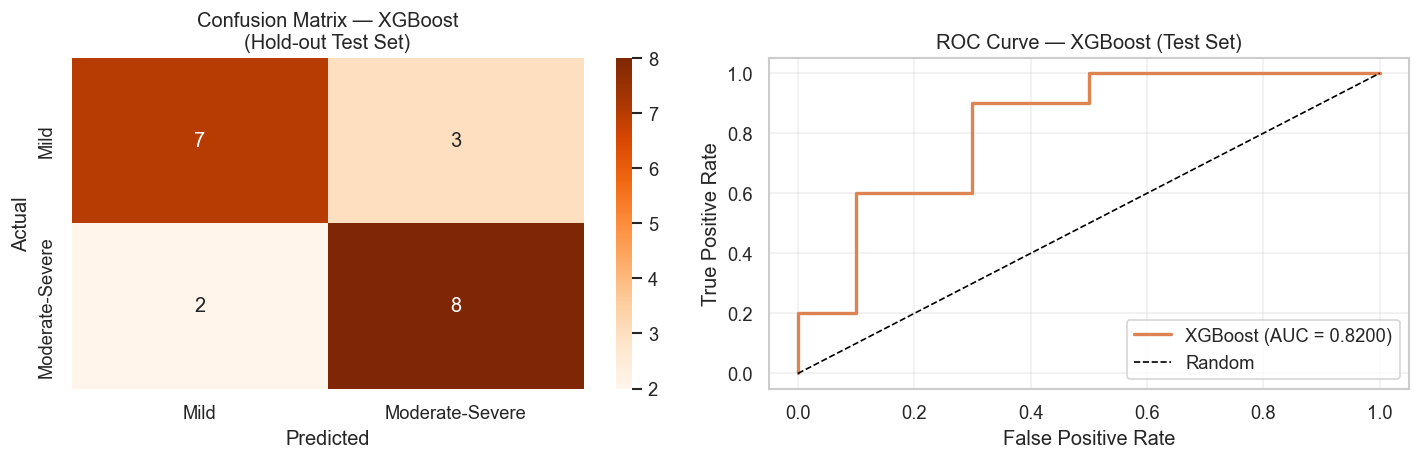


  Section 6 — Ringkasan XGBoost (Exp 2)
  [K-Fold Val]  Accuracy : 0.5750 ± 0.1355
  [K-Fold Val]  F1-Score : 0.5983 ± 0.1470
  [K-Fold Val]  AUC-ROC  : 0.6062 ± 0.1783
  ────────────────────────────────────────
  [Test Set]    Accuracy : 0.7500
  [Test Set]    F1-Score : 0.7619
  [Test Set]    AUC-ROC  : 0.8200
  [Test Set]    FN kritis: 2 dari 10 MS
  Variabel aktif: results_xgb2, final_model_xgb2, cm_xgb2
  Lanjut ke Cell 11 — MLP + K-Fold


In [11]:
# CELL 10 — XGBOOST + K-FOLD (DATA AUGMENTED)
# Deskripsi: Training XGBoost pada X_train (80 sampel
#            augmented) dengan Stratified K-Fold (k=5).
#            Evaluasi akhir pada X_test (20 sampel hold-out).
#            Parameter identik Eksperimen 1 untuk komparasi.
# ============================================================

XGB_PARAMS = {
    'n_estimators'    : 100,
    'learning_rate'   : 0.1,
    'max_depth'       : 3,
    'subsample'       : 0.8,
    'colsample_bytree': 0.8,
    'use_label_encoder': False,
    'eval_metric'     : 'logloss',
    'random_state'    : 42,
    'verbosity'       : 0
}

# ── Section 1: Konfigurasi ────────────────────────────────────
print("=" * 60)
print("Section 1: XGBoost — Konfigurasi Model")
print("=" * 60)
print("  Algoritma     : XGBoost Classifier")
print(f"  Dataset        : X_train {X_train.shape} (augmented)")
for k, v in XGB_PARAMS.items():
    print(f"  {k:<22}: {v}")

# ── Section 2: Training K-Fold ────────────────────────────────
print("\nSection 2: Training Stratified K-Fold (pada X_train)")
print("-" * 60)
print(f"  {'Fold':<6} {'Acc':>6} {'Prec':>6} {'Rec':>6} {'F1':>6} {'AUC':>6}")
print(f"  {'-'*38}")

fold_metrics_xgb2  = []
all_y_true_val_xgb2 = []
all_y_pred_val_xgb2 = []
all_y_prob_val_xgb2 = []
best_model_xgb2     = None
best_f1_xgb2        = -1

for fold, (tr_idx, vl_idx) in enumerate(
        kfold.split(X_train, y_train), 1):

    X_tr, X_vl = X_train[tr_idx], X_train[vl_idx]
    y_tr, y_vl = y_train[tr_idx], y_train[vl_idx]

    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_vl_sc = scaler.transform(X_vl)

    model = XGBClassifier(**XGB_PARAMS)
    model.fit(X_tr_sc, y_tr)

    y_pred    = model.predict(X_vl_sc)
    y_prob    = model.predict_proba(X_vl_sc)[:, 1]

    acc       = accuracy_score(y_vl, y_pred)
    prec      = precision_score(y_vl, y_pred, zero_division=0)
    rec       = recall_score(y_vl, y_pred, zero_division=0)
    f1        = f1_score(y_vl, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_vl, y_prob)

    fold_metrics_xgb2.append({
        'fold': fold, 'acc': acc,       'prec': prec,
        'rec' : rec,  'f1' : f1,        'auc' : auc_score
    })
    all_y_true_val_xgb2.extend(y_vl)
    all_y_pred_val_xgb2.extend(y_pred)
    all_y_prob_val_xgb2.extend(y_prob)

    if f1 > best_f1_xgb2:
        best_f1_xgb2    = f1
        best_model_xgb2 = model
        best_scaler_xgb2 = scaler

    print(f"  Fold {fold}  {acc:.4f} {prec:.4f} {rec:.4f} {f1:.4f} {auc_score:.4f}")

# ── Section 3: Rata-rata Metrik K-Fold ───────────────────────
print(f"\nSection 3: Rata-rata Metrik K-Fold (Mean ± Std)")
print("-" * 60)

df_fold_xgb2 = pd.DataFrame(fold_metrics_xgb2)
metrics_list = ['acc', 'prec', 'rec', 'f1', 'auc']
label_map    = {
    'acc':'Accuracy', 'prec':'Precision', 'rec':'Recall',
    'f1':'F1-Score',  'auc':'AUC-ROC'
}

results_xgb2 = {}
for m in metrics_list:
    mean = df_fold_xgb2[m].mean()
    std  = df_fold_xgb2[m].std()
    results_xgb2[m] = {'mean': mean, 'std': std}
    print(f"  {label_map[m]:<11}: {mean:.4f} ± {std:.4f}")

# ── Section 4: Evaluasi Final pada X_test ────────────────────
print(f"\nSection 4: Evaluasi Final pada X_test (Hold-out 20%)")
print("-" * 60)

scaler_final_xgb2 = StandardScaler()
X_train_sc_final  = scaler_final_xgb2.fit_transform(X_train)
X_test_sc_final   = scaler_final_xgb2.transform(X_test)

final_model_xgb2  = XGBClassifier(**XGB_PARAMS)
final_model_xgb2.fit(X_train_sc_final, y_train)

y_pred_test_xgb2  = final_model_xgb2.predict(X_test_sc_final)
y_prob_test_xgb2  = final_model_xgb2.predict_proba(X_test_sc_final)[:, 1]

test_acc_xgb2  = accuracy_score(y_test, y_pred_test_xgb2)
test_prec_xgb2 = precision_score(y_test, y_pred_test_xgb2, zero_division=0)
test_rec_xgb2  = recall_score(y_test, y_pred_test_xgb2, zero_division=0)
test_f1_xgb2   = f1_score(y_test, y_pred_test_xgb2, zero_division=0)
test_auc_xgb2  = roc_auc_score(y_test, y_prob_test_xgb2)

print(f"  Accuracy  : {test_acc_xgb2:.4f}")
print(f"  Precision : {test_prec_xgb2:.4f}")
print(f"  Recall    : {test_rec_xgb2:.4f}")
print(f"  F1-Score  : {test_f1_xgb2:.4f}")
print(f"  AUC-ROC   : {test_auc_xgb2:.4f}")

# ── Section 5: Confusion Matrix + Classification Report ──────
print(f"\nSection 5: Confusion Matrix + Classification Report")
print("-" * 60)

cm_xgb2 = confusion_matrix(y_test, y_pred_test_xgb2)
print(f"  TN={cm_xgb2[0,0]}  FP={cm_xgb2[0,1]}")
print(f"  FN={cm_xgb2[1,0]}  TP={cm_xgb2[1,1]}")
print(f"\n  Interpretasi:")
print(f"  TP (MS terdeteksi benar)         : {cm_xgb2[1,1]}")
print(f"  TN (Mild terdeteksi benar)       : {cm_xgb2[0,0]}")
print(f"  FP (Mild salah prediksi jadi MS) : {cm_xgb2[0,1]}")
print(f"  FN (MS terlewat — kritis)        : {cm_xgb2[1,0]}")

print(f"\n  Classification Report (X_test):")
print(classification_report(
    y_test, y_pred_test_xgb2,
    target_names=['Mild (0)', 'Moderate-Severe (1)'],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm_xgb2, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Mild', 'Moderate-Severe'],
            yticklabels=['Mild', 'Moderate-Severe'],
            ax=axes[0])
axes[0].set_title(
    'Confusion Matrix — XGBoost\n(Hold-out Test Set)')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

fpr_xgb2, tpr_xgb2, _ = roc_curve(y_test, y_prob_test_xgb2)
roc_val_xgb2            = auc(fpr_xgb2, tpr_xgb2)
axes[1].plot(fpr_xgb2, tpr_xgb2, color='#DD8452', lw=2,
             label=f'XGBoost (AUC = {roc_val_xgb2:.4f})')
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — XGBoost (Test Set)')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('xgb2_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Section 6: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 6 — Ringkasan XGBoost (Exp 2)")
print("=" * 60)
print(f"  [K-Fold Val]  Accuracy : {results_xgb2['acc']['mean']:.4f} ± {results_xgb2['acc']['std']:.4f}")
print(f"  [K-Fold Val]  F1-Score : {results_xgb2['f1']['mean']:.4f} ± {results_xgb2['f1']['std']:.4f}")
print(f"  [K-Fold Val]  AUC-ROC  : {results_xgb2['auc']['mean']:.4f} ± {results_xgb2['auc']['std']:.4f}")
print(f"  {'─'*40}")
print(f"  [Test Set]    Accuracy : {test_acc_xgb2:.4f}")
print(f"  [Test Set]    F1-Score : {test_f1_xgb2:.4f}")
print(f"  [Test Set]    AUC-ROC  : {test_auc_xgb2:.4f}")
print(f"  [Test Set]    FN kritis: {cm_xgb2[1,0]} dari {sum(y_test==1)} MS")
print("=" * 60)
print("  Variabel aktif: results_xgb2, final_model_xgb2, cm_xgb2")
print("  Lanjut ke Cell 11 — MLP + K-Fold")

Section 1: MLP — Konfigurasi Model
  Algoritma     : Multi-Layer Perceptron
  Arsitektur     : Input(47) → Dense(64) → Dense(32) → Output(1)
  Dataset        : X_train (80, 47) (augmented)
  hidden_layer_sizes    : (64, 32)
  activation            : relu
  solver                : adam
  alpha                 : 0.01
  learning_rate         : adaptive
  learning_rate_init    : 0.001
  max_iter              : 500
  early_stopping        : True
  validation_fraction   : 0.1
  n_iter_no_change      : 20
  random_state          : 42

Section 2: Training Stratified K-Fold (pada X_train)
------------------------------------------------------------
  Fold      Acc   Prec    Rec     F1    AUC   Iter
  ---------------------------------------------
  Fold 1  0.6250 0.6667 0.5000 0.5714 0.5625    37
  Fold 2  0.7500 0.8333 0.6250 0.7143 0.9062    36
  Fold 3  0.6875 1.0000 0.3750 0.5455 0.7188    22
  Fold 4  0.5625 0.6000 0.3750 0.4615 0.6562    25
  Fold 5  0.5625 0.5714 0.5000 0.5333 0.6094    2

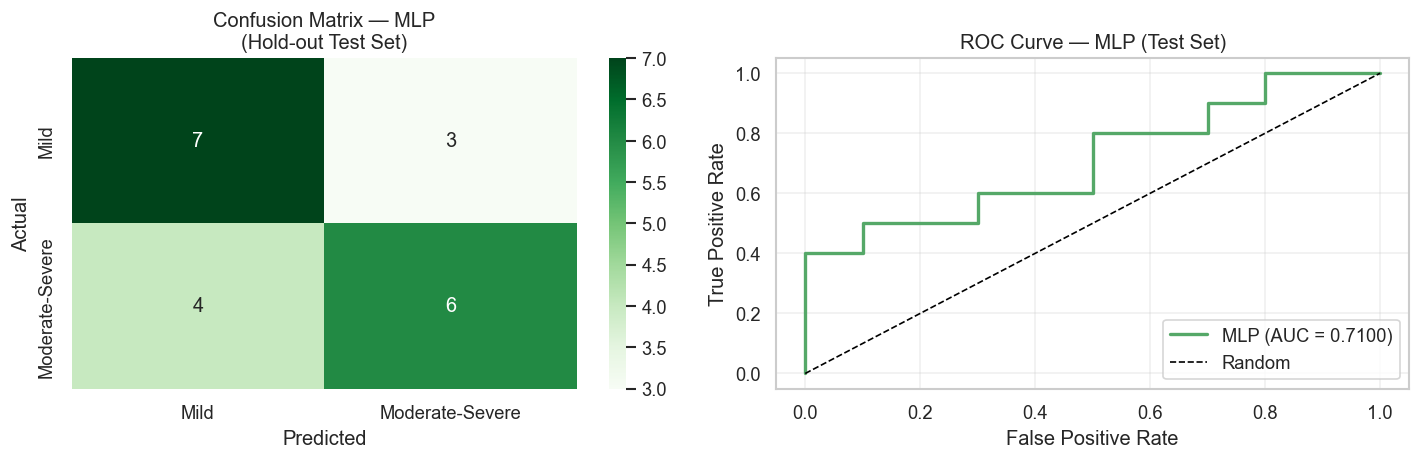


  Section 6 — Ringkasan MLP (Exp 2)
  [K-Fold Val]  Accuracy : 0.6375 ± 0.0815
  [K-Fold Val]  F1-Score : 0.5652 ± 0.0928
  [K-Fold Val]  AUC-ROC  : 0.6906 ± 0.1337
  ────────────────────────────────────────
  [Test Set]    Accuracy : 0.6500
  [Test Set]    F1-Score : 0.6316
  [Test Set]    AUC-ROC  : 0.7100
  [Test Set]    FN kritis: 4 dari 10 MS
  Variabel aktif: results_mlp2, final_model_mlp2, cm_mlp2
  Lanjut ke Cell 12 — Evaluasi Komparatif


In [12]:
# CELL 11 — MLP + K-FOLD (DATA AUGMENTED)
# Deskripsi: Training MLP pada X_train (80 sampel augmented)
#            dengan Stratified K-Fold (k=5).
#            Evaluasi akhir pada X_test (20 sampel hold-out).
#            Parameter identik Eksperimen 1 untuk komparasi.
# ============================================================

MLP_PARAMS = {
    'hidden_layer_sizes' : (64, 32),
    'activation'         : 'relu',
    'solver'             : 'adam',
    'alpha'              : 0.01,
    'learning_rate'      : 'adaptive',
    'learning_rate_init' : 0.001,
    'max_iter'           : 500,
    'early_stopping'     : True,
    'validation_fraction': 0.1,
    'n_iter_no_change'   : 20,
    'random_state'       : 42
}

# ── Section 1: Konfigurasi ────────────────────────────────────
print("=" * 60)
print("Section 1: MLP — Konfigurasi Model")
print("=" * 60)
print("  Algoritma     : Multi-Layer Perceptron")
print(f"  Arsitektur     : Input(47) → Dense(64) → Dense(32) → Output(1)")
print(f"  Dataset        : X_train {X_train.shape} (augmented)")
for k, v in MLP_PARAMS.items():
    print(f"  {k:<22}: {v}")

# ── Section 2: Training K-Fold ────────────────────────────────
print("\nSection 2: Training Stratified K-Fold (pada X_train)")
print("-" * 60)
print(f"  {'Fold':<6} {'Acc':>6} {'Prec':>6} {'Rec':>6} {'F1':>6} {'AUC':>6} {'Iter':>6}")
print(f"  {'-'*45}")

fold_metrics_mlp2   = []
all_y_true_val_mlp2 = []
all_y_pred_val_mlp2 = []
all_y_prob_val_mlp2 = []
best_model_mlp2     = None
best_f1_mlp2        = -1

for fold, (tr_idx, vl_idx) in enumerate(
        kfold.split(X_train, y_train), 1):

    X_tr, X_vl = X_train[tr_idx], X_train[vl_idx]
    y_tr, y_vl = y_train[tr_idx], y_train[vl_idx]

    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_vl_sc = scaler.transform(X_vl)

    model  = MLPClassifier(**MLP_PARAMS)
    model.fit(X_tr_sc, y_tr)

    y_pred    = model.predict(X_vl_sc)
    y_prob    = model.predict_proba(X_vl_sc)[:, 1]
    n_iter    = model.n_iter_

    acc       = accuracy_score(y_vl, y_pred)
    prec      = precision_score(y_vl, y_pred, zero_division=0)
    rec       = recall_score(y_vl, y_pred, zero_division=0)
    f1        = f1_score(y_vl, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_vl, y_prob)

    fold_metrics_mlp2.append({
        'fold': fold, 'acc': acc,       'prec': prec,
        'rec' : rec,  'f1' : f1,        'auc' : auc_score
    })
    all_y_true_val_mlp2.extend(y_vl)
    all_y_pred_val_mlp2.extend(y_pred)
    all_y_prob_val_mlp2.extend(y_prob)

    if f1 > best_f1_mlp2:
        best_f1_mlp2    = f1
        best_model_mlp2 = model
        best_scaler_mlp2 = scaler

    print(f"  Fold {fold}  {acc:.4f} {prec:.4f} {rec:.4f} "
          f"{f1:.4f} {auc_score:.4f} {n_iter:>5}")

# ── Section 3: Rata-rata Metrik K-Fold ───────────────────────
print(f"\nSection 3: Rata-rata Metrik K-Fold (Mean ± Std)")
print("-" * 60)

df_fold_mlp2 = pd.DataFrame(fold_metrics_mlp2)
metrics_list = ['acc', 'prec', 'rec', 'f1', 'auc']
label_map    = {
    'acc':'Accuracy', 'prec':'Precision', 'rec':'Recall',
    'f1':'F1-Score',  'auc':'AUC-ROC'
}

results_mlp2 = {}
for m in metrics_list:
    mean = df_fold_mlp2[m].mean()
    std  = df_fold_mlp2[m].std()
    results_mlp2[m] = {'mean': mean, 'std': std}
    print(f"  {label_map[m]:<11}: {mean:.4f} ± {std:.4f}")

# ── Section 4: Evaluasi Final pada X_test ────────────────────
print(f"\nSection 4: Evaluasi Final pada X_test (Hold-out 20%)")
print("-" * 60)

scaler_final_mlp2 = StandardScaler()
X_train_sc_final  = scaler_final_mlp2.fit_transform(X_train)
X_test_sc_final   = scaler_final_mlp2.transform(X_test)

final_model_mlp2  = MLPClassifier(**MLP_PARAMS)
final_model_mlp2.fit(X_train_sc_final, y_train)

y_pred_test_mlp2  = final_model_mlp2.predict(X_test_sc_final)
y_prob_test_mlp2  = final_model_mlp2.predict_proba(X_test_sc_final)[:, 1]

test_acc_mlp2  = accuracy_score(y_test, y_pred_test_mlp2)
test_prec_mlp2 = precision_score(y_test, y_pred_test_mlp2, zero_division=0)
test_rec_mlp2  = recall_score(y_test, y_pred_test_mlp2, zero_division=0)
test_f1_mlp2   = f1_score(y_test, y_pred_test_mlp2, zero_division=0)
test_auc_mlp2  = roc_auc_score(y_test, y_prob_test_mlp2)

print(f"  Accuracy  : {test_acc_mlp2:.4f}")
print(f"  Precision : {test_prec_mlp2:.4f}")
print(f"  Recall    : {test_rec_mlp2:.4f}")
print(f"  F1-Score  : {test_f1_mlp2:.4f}")
print(f"  AUC-ROC   : {test_auc_mlp2:.4f}")

# ── Section 5: Confusion Matrix + Classification Report ──────
print(f"\nSection 5: Confusion Matrix + Classification Report")
print("-" * 60)

cm_mlp2 = confusion_matrix(y_test, y_pred_test_mlp2)
print(f"  TN={cm_mlp2[0,0]}  FP={cm_mlp2[0,1]}")
print(f"  FN={cm_mlp2[1,0]}  TP={cm_mlp2[1,1]}")
print(f"\n  Interpretasi:")
print(f"  TP (MS terdeteksi benar)         : {cm_mlp2[1,1]}")
print(f"  TN (Mild terdeteksi benar)       : {cm_mlp2[0,0]}")
print(f"  FP (Mild salah prediksi jadi MS) : {cm_mlp2[0,1]}")
print(f"  FN (MS terlewat — kritis)        : {cm_mlp2[1,0]}")

print(f"\n  Classification Report (X_test):")
print(classification_report(
    y_test, y_pred_test_mlp2,
    target_names=['Mild (0)', 'Moderate-Severe (1)'],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm_mlp2, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Mild', 'Moderate-Severe'],
            yticklabels=['Mild', 'Moderate-Severe'],
            ax=axes[0])
axes[0].set_title(
    'Confusion Matrix — MLP\n(Hold-out Test Set)')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

fpr_mlp2, tpr_mlp2, _ = roc_curve(y_test, y_prob_test_mlp2)
roc_val_mlp2            = auc(fpr_mlp2, tpr_mlp2)
axes[1].plot(fpr_mlp2, tpr_mlp2, color='#55A868', lw=2,
             label=f'MLP (AUC = {roc_val_mlp2:.4f})')
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — MLP (Test Set)')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('mlp2_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Section 6: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 6 — Ringkasan MLP (Exp 2)")
print("=" * 60)
print(f"  [K-Fold Val]  Accuracy : {results_mlp2['acc']['mean']:.4f} ± {results_mlp2['acc']['std']:.4f}")
print(f"  [K-Fold Val]  F1-Score : {results_mlp2['f1']['mean']:.4f} ± {results_mlp2['f1']['std']:.4f}")
print(f"  [K-Fold Val]  AUC-ROC  : {results_mlp2['auc']['mean']:.4f} ± {results_mlp2['auc']['std']:.4f}")
print(f"  {'─'*40}")
print(f"  [Test Set]    Accuracy : {test_acc_mlp2:.4f}")
print(f"  [Test Set]    F1-Score : {test_f1_mlp2:.4f}")
print(f"  [Test Set]    AUC-ROC  : {test_auc_mlp2:.4f}")
print(f"  [Test Set]    FN kritis: {cm_mlp2[1,0]} dari {sum(y_test==1)} MS")
print("=" * 60)
print("  Variabel aktif: results_mlp2, final_model_mlp2, cm_mlp2")
print("  Lanjut ke Cell 12 — Evaluasi Komparatif")